## Ferramentas
Como ferramental, estou utilizando Jupyter Notebook rodando através do Visual Studio. <br>

## Caso de referência
Para o desenvolvimento do projeto utilizaremos os dados relativos ao PNAE. <br>

Elaborar o processo exploratório de dados no papel de um cientista. <br>

<b>Origem dos dados<br>
https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/pnae/media-pnae/Planilha_PlanPNAE_versao_4atualizada221121.xlsx <br>
https://sidra.ibge.gov.br/tabela/7060 <br>
https://www.ba.gov.br/sde/publicacoes/Tabela%20de%20Pre%C3%A7os%20Ceasa <br>

# Import
Começaremos importando as bibliotecas que utilizaremos neste projeto. <br>
Estão omitidos os comandos de instalação. Portanto, ao replicar o código, lembrar de instalar (pip install) antes de importar. <br>

Ingestão
- Automatize o download dos arquivos (o que for possível)
- Defina o que interessa dentro dos arquivos (aba da planilha)
- Trate cores que representam classificações de restrições
ETL
- Descarte colunas desnecessárias ou organize tabelas de relacionamento
- Faça o tratamento adequado dos formatos de dados (float)
- Verifique dados faltantes, defina estratégia (descarte ou inputação) e métodos para preenchimento (enriquecimento com outra fonte, estimativa, etc)
- Descarte linhas em branco e duplicatas
- Criação de grupos alimentares
Análise Exploratória
- Análise da composição nutrucional
- Análise por grupo alimentar
- Análise por classificação de restrição
- Análise para elaboração de cardápio
- Análise estátistica

Perguntas com dados presentes no dataset:

Perguntas sobre composição nutricional
- Quais alimentos possuem maior teor de proteína por 100g?
- Quais alimentos possuem menor densidade energética?
- Quais alimentos têm maior quantidade de fibras?
- Quais alimentos apresentam maior teor de sódio?
- Quais alimentos possuem maior concentração de cálcio, ferro, zinco ou vitamina A?
- Quais alimentos são mais ricos em carboidratos?
- Quais alimentos apresentam maior quantidade de gorduras totais?
- Qual grupo alimentar possui maior média de calorias?
- Existe correlação entre calorias e teor de gordura?
- Quais alimentos têm perfil nutricional mais equilibrado?
- Quais alimentos possuem melhor relação proteína/caloria?
- Quais alimentos possuem alta densidade nutricional?
- Quais micronutrientes aparecem com maior frequência em alimentos naturais?

Perguntas sobre grupos alimentares
- Quantos alimentos existem por grupo alimentar?
- Quais grupos possuem maior variedade de itens?
- Quais grupos apresentam maior média de sódio?
- Quais grupos concentram alimentos mais energéticos?
- Qual grupo possui alimentos mais ricos em ferro?
- Qual grupo concentra maior quantidade de ultraprocessados/restritos?
- Há predominância de alimentos vegetais ou animais no cadastro?

Os alimentos são destacados com cores categorizam a aquisição no PNAE. Assim, o dataset permite perguntas como:
- Quais alimentos são classificados como aquisição restrita?
- Quantos alimentos restritos existem no banco?
- Qual percentual do total de alimentos é restrito?
- Quais grupos alimentares concentram mais itens restritos?
- Quais nutrientes predominam em alimentos restritos?
- Alimentos restritos possuem maior densidade calórica?
- Alimentos restritos possuem maior teor de sódio ou açúcar?
- Existem alternativas nutricionalmente equivalentes aos alimentos restritos?

Como o PLAN PNAE foi criado para elaboração de cardápios escolares, o dataset permite análises como:
- Quais alimentos ajudam a atingir metas de proteína?
- Quais alimentos ajudam a reduzir sódio no cardápio?
- Quais combinações de alimentos melhor atendem às recomendações nutricionais?
- Quais alimentos podem substituir itens mais caros?
- Quais alimentos ajudam a atingir metas de ferro ou cálcio?
- Quais alimentos possuem maior densidade nutricional para merenda escolar?
- Quais alimentos são mais adequados para cardápios de baixo custo?
- Quais ingredientes elevam mais rapidamente o teor calórico das refeições?
- Quais alimentos devem ser evitados em excesso devido ao sódio?
- Quais alimentos podem ser usados para enriquecer refeições vegetarianas?

Perguntas estatísticas e de qualidade de dados
- Existem inconsistências entre grupos alimentares e composição nutricional?
- Qual a distribuição das calorias entre os alimentos?
- Qual a distribuição de proteínas por grupo?
- Existem outliers nutricionais?
- Quais colunas possuem maior variabilidade?
- Quais nutrientes possuem maior dispersão estatística?

Perguntas avançadas
- É possível clusterizar alimentos por perfil nutricional?
- Quais alimentos são nutricionalmente semelhantes?
- Quais grupos alimentares explicam maior variabilidade nutricional?
- É possível identificar alimentos ultraprocessados pelo perfil nutricional?
- Quais alimentos dominam múltiplos nutrientes simultaneamente?

# Data Wrangling

* Tamanho
* Limpeza e duplicidade (linhas e colunas)
* Tipagem
   * Tratamento de número
* Tidy data: regex
* Dados faltantes e imputação de dados
   * pandas
   * Descartes: linhas com dados faltantes, colunas com dados faltantes
   * Criação de colunas
   * Medidas estatísticas: média, mediana, aleatório baseado na distribuição
   * Modelos preditivos
* Outliers
   * Univariado: IQR
* Distribuição (numéricas)
* Scaling: normalization, standardization, robust
* Representatividade das classes (categóricas)
* Correlações: variáveis númericas e categóricas
* Redução de dimensionalidade
   * PCA

## Importar bibliotecas e configurações iniciais

In [83]:
# importação das bibliotecas
import pandas as pd
import numpy as np

import requests
from io import BytesIO

import matplotlib.pyplot as plt
import seaborn as sns

# Para lidar com caracteres acentuados
import unicodedata 

# Para normalização semântica e matching
import re
from rapidfuzz import process, fuzz 

from openpyxl import load_workbook
import warnings

# Silenciar apenas avisos específicos do openpyxl
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")


# Configurações visuais
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## Carregar planilha de alimentos do PNAE

In [84]:
# padrao de pastas para projetos de dados
input_folder = './data/input/'
output_folder = './data/output/'

# Localização do arquivo
arquivo = "https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/pnae/media-pnae/Planilha_PlanPNAE_versao_4atualizada221121.xlsx"


# Baixar arquivo
response = requests.get(arquivo)
response.raise_for_status()

# Carregar workbook em memória a partir do conteúdo baixado - data_only=True -> lê valores calculados
wb = load_workbook(BytesIO(response.content), data_only=True)

# Verificar abas da planilha
print("Abas disponíveis:")
print(wb.sheetnames)

# Selecionar aba principal - 'Tabela de alimentos' que está na posição 0
ws = wb[wb.sheetnames[0]]
print(f"\nAba carregada: {ws.title}")



Abas disponíveis:
['Tabela de alimentos', 'Ficha técnica', 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Média semanal (Creche)', 'Média semanal (> 3 anos)', 'Custos dos cardápios']

Aba carregada: Tabela de alimentos


## Ler a planilha preservando as cores das células e transformar as cores em categorias restritivas

In [85]:
# Ler a planilha preservando as cores das células e transformar as cores em categorias restritivas.
#
# Regras:
#
# Cor da célula M2: -> "Aquisição proibida"
# Cor da célula N2: -> "Oferta limitada para > 3 anos e proibida para ≤ 3 anos"
# Cor da célula O2: -> "Oferta limitada para todas as idades"
#
# A classificação será aplicada aos elementos da coluna A
# conforme a cor da célula correspondente.

# Função para extrair a cor da célula e retornar um RGB ou tema.
def get_rgb_color(cell):
    color = cell.fill.fgColor
    if color.type == 'rgb':
        return str(color.rgb)
    elif color.type == 'theme':
        # Se for cor de tema, o openpyxl não converte automaticamente para RGB 
        # sem ler o XML do tema. Para este caso específico do PNAE, 
        # retornamos o índice do tema como string.
        return f"theme_{color.theme}"
    return str(color.index)

# Capturar as cores presentes de referência em:
# M2, N2 e O2
cor_m2 = get_rgb_color(ws["M2"])
cor_n2 = get_rgb_color(ws["N2"])
cor_o2 = get_rgb_color(ws["O2"])

print("\nCores de referência detectadas:")
print(f"M2 (Vermelho): {cor_m2}")
print(f"N2 (Amarelo): {cor_n2}")
print(f"O2 (Laranja/Outro): {cor_o2}")

# Mapa de cores atualizado
mapa_cores = {
    cor_m2: "Aquisição proibida",
    cor_n2: "Oferta limitada para > 3 anos e proibida para ≤ 3 anos",
    cor_o2: "Oferta limitada para todas as idades"
}

print(f"Cores de referência normalizadas: {mapa_cores}") 

# Extrair os dados da aba 'Tabela de alimentos' para um DataFrame

# Lista para armazenar linhas
dados = []

# Lista para armazenar classificações por cor
restricoes = []

# Capturar cabeçalhos diretamente da primeira linha da aba ativa
headers = [cell.value for cell in ws[1]]

# Percorrer linhas da planilha para extrair dados e classificar por cor
for row in ws.iter_rows(min_row=2):
    valores = [cell.value for cell in row]
    dados.append(valores)

    # Captura segura da cor na Coluna A
    cor_atual = get_rgb_color(row[0])
    restricao = mapa_cores.get(cor_atual, "Sem restrição")
    restricoes.append(restricao)



Cores de referência detectadas:
M2 (Vermelho): FFFF0000
N2 (Amarelo): FFFFFF00
O2 (Laranja/Outro): theme_8
Cores de referência normalizadas: {'FFFF0000': 'Aquisição proibida', 'FFFFFF00': 'Oferta limitada para > 3 anos e proibida para ≤ 3 anos', 'theme_8': 'Oferta limitada para todas as idades'}


## Criar DataFrame

In [86]:
 # Criar DataFrame
df = pd.DataFrame(dados, columns=headers)

# Informar sobre o processamento concluído e a estrutura do DataFrame
print(f"Processamento concluído. DataFrame criado com {len(df)} linhas e {len(df.columns)} colunas.")

# Visualizar primeiras linhas
display(df.head())

# Estrutura do dataset
print("\nInformações gerais:")
print(df.describe())
print(df.info())

Processamento concluído. DataFrame criado com 935 linhas e 15 colunas.


,Tabela de composição em 100g de alimento,Energia,NaN,Proteína,Lipídeos,Carboidratos,Cálcio,Ferro,Retinol,Vitamina C,Sódio,Legenda:,Aquisição proibida,Oferta limitada para > 3 anos e proibida para ≤ 3 anos de idade,Oferta limitada para todas as idades
0,Descrição dos alimentos,(kcal),(kJ),(g),(g),(g),(mg),(mg),(mcg),(mg),(mg),NaN,None,None,None
1,"Abacate, cru",96.154709,402.311301,1.23913,8.396667,6.03087,7.916667,0.206667,61.2,8.66,0,Fonte: Resolução CD/FNDE nº 06/2020,None,None,None
2,"Abacaxi, banana e cenoura, suco natural (nécta...",64,267.776,0.57,0.14,15.7,10.5,0.26,235,7.96,5.19,NaN,None,None,None
3,"Abacaxi, banana e cenoura, suco natural (nécta...",28,117.152,0.61,0.15,6.59,11.3,0.28,261,8.82,4.43,NaN,None,None,None
4,"Abacaxi, cru",48.322213,202.180139,0.858696,0.123333,12.334638,22.433333,0.256667,2.3,34.623333,0,NaN,None,None,None



Informações gerais:
       Tabela de composição em 100g de alimento  Energia       NaN  Proteína  \
count                                       585      585   585.000       585   
unique                                      580      531   532.000       508   
top              Almôndega ao molho em conserva      884  3698.656         0   
freq                                          2        8     8.000        30   

        Lipídeos  Carboidratos  Cálcio  Ferro  Retinol  Vitamina C  Sódio  \
count        585           585     585    585      585         585    585   
unique       449           465     521    434      221         271    420   
top            0             0       0      0        0           0      0   
freq          41           102      22     36      279         302     80   

                                   Legenda: Aquisição proibida  \
count                                     1                  0   
unique                                    1                 

## Análise de tratamentos iniciais
1. Precisa manter todas as colunas? Não, há colunas desnecessárias como 'legenda:' e 'coluna_vazia'. 
2. Energia tem duas unidades de medida, formando a coluna 'energia' com dados de kcal e 'coluna_vazia' com dados de kJ. Para energia será considerada kcal e excluída a de kJ. 
3. As cores utililzadas são relevantes para o contexto? Sim, pois elas categorizam as restrições dos alimentos.  
4. Faltam colunas? Falta uma nova coluna com a categoria de restrição do alimento.
5. Existe preço dos alimentos na tabela de alimentos? Não.
6. Com quais tabelas iremos relacionar? Será preciso usar outro dataset de preço. 
7. Existem linhas em branco e duplicadas no dataset que precisam ser excluídas.

## Limpeza e tratamento dos dados
### Colunas

In [87]:
# Padronização dos nomes das colunas

# Função para remover acentos
def remover_acentos(texto):
    if not isinstance(texto, str):
        return texto
    return ''.join(
        char for char in unicodedata.normalize('NFD', texto)
        if unicodedata.category(char) != 'Mn'
    )

# Remover acentos e caracteres especiais com tratamento de nulos
df.columns = [
    remover_acentos(str(c)).strip().lower() if c is not None else "coluna_vazia" 
    for c in df.columns
]

# Remover espaços extras
# Converter para minúsculas
# Substituir espaços por "_"

df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_")
      .str.replace("(", "", regex=False)
      .str.replace(")", "", regex=False)
      .str.replace("/", "_")
)

print("\nColunas padronizadas:")
print(df.columns.tolist())



Colunas padronizadas:
['tabela_de_composicao_em_100g_de_alimento', 'energia', 'nan', 'proteina', 'lipideos', 'carboidratos', 'calcio', 'ferro', 'retinol', 'vitamina_c', 'sodio', 'legenda:', 'aquisicao_proibida', 'oferta_limitada_para_>_3_anos_e_proibida_para_≤_3_anos_de_idade', 'oferta_limitada_para_todas_as_idades']


In [88]:
# Ajustes nas COLUNAS
# Adicionar coluna de restrição baseada na cor da célula da Coluna A
df["restricao_pnae"] = restricoes

# Renomear a primeira coluna para 'alimento'
df.rename(columns={df.columns[0]: 'alimento'}, inplace=True)

# Remover colunas
colunas_para_remover = [
    'coluna_vazia',
    'legenda:',
    'aquisicao_proibida',
    'oferta_limitada_para_>_3_anos_e_proibida_para_≤_3_anos_de_idade',
    'oferta_limitada_para_todas_as_idades'
]

colunas_existentes = [c for c in colunas_para_remover if c in df.columns]
if colunas_existentes:
    df = df.drop(columns=colunas_existentes)

print("\nColunas atuais:")
print(df.columns.tolist())

# Visualizar primeiras e últimas linhas
display(df.head())
display(df.tail())


Colunas atuais:
['alimento', 'energia', 'nan', 'proteina', 'lipideos', 'carboidratos', 'calcio', 'ferro', 'retinol', 'vitamina_c', 'sodio', 'restricao_pnae']


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae
0,Descrição dos alimentos,(kcal),(kJ),(g),(g),(g),(mg),(mg),(mcg),(mg),(mg),Sem restrição
1,"Abacate, cru",96.154709,402.311301,1.23913,8.396667,6.03087,7.916667,0.206667,61.2,8.66,0,Sem restrição
2,"Abacaxi, banana e cenoura, suco natural (nécta...",64,267.776,0.57,0.14,15.7,10.5,0.26,235,7.96,5.19,Oferta limitada para > 3 anos e proibida para ...
3,"Abacaxi, banana e cenoura, suco natural (nécta...",28,117.152,0.61,0.15,6.59,11.3,0.28,261,8.82,4.43,Sem restrição
4,"Abacaxi, cru",48.322213,202.180139,0.858696,0.123333,12.334638,22.433333,0.256667,2.3,34.623333,0,Sem restrição


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae
930,NaN,None,None,None,None,None,None,None,None,None,None,Sem restrição
931,NaN,None,None,None,None,None,None,None,None,None,None,Sem restrição
932,NaN,None,None,None,None,None,None,None,None,None,None,Sem restrição
933,NaN,None,None,None,None,None,None,None,None,None,None,Sem restrição
934,NaN,None,None,None,None,None,None,None,None,None,None,Sem restrição


### Colunas - tratamento dos dados

In [89]:
# Tratamento dos dados

# Substituir caracteres problemáticos
# Exemplo: vírgulas decimais

for col in df.columns:
    
    # Converter apenas colunas object
    if df[col].dtype == 'object':
        
        df[col] = (
            df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
            .str.strip()
        )

# Converter colunas numéricas

# Lista preliminar de possíveis colunas numéricas
colunas_numericas = [
    c for c in df.columns
    if any(p in c for p in [
        "energia",
        "proteina",
        "lipideos",
        "carboidrato",
        "calcio",   
        "ferro",    
        "retinol",
        "vitamina_c",
        "sodio",
    ])
]


# Converter para float
# Float o computador armazena a maior precisão possível para garantir a integridade dos cálculos
for col in colunas_numericas:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("\nConversão para float concluída.")


Conversão para float concluída.


### Linhas

In [90]:
# Limpeza dos dados
# Apagar a segunda linha (índice 0 dos dados) que contém informações de legenda e não é relevante para as análises
df = df.drop(index=0)

# Remover linhas completamente em branco (que podem existir no final da planilha)
df = df.dropna(how='all')

# Remover linhas que a coluna "alimento" esteja vazia ou nula, pois são essenciais para as análises
# Já que sem o nome do alimento, os dados nutricionais não fazem sentido.
# Converte a string "None" (criada pelo astype(str)) em nulo real do numpy
df['alimento'] = df['alimento'].replace('None', np.nan)
df = df.dropna(subset=['alimento'])


# Remover linhas duplicadas
print("\nVerificação de linhas duplicadas:")
print(df.duplicated().sum())
df = df.drop_duplicates()
print("\nLinhas duplicadas após remoção:")
print(df.duplicated().sum())

# Resetar os índices
df = df.reset_index(drop=True)


# Visualizar primeiras e últimas linhas
display(df.head())
display(df.tail())


# Verificar se a linha com alimento vazio/none ainda existe
print(f"Processamento concluído. DataFrame final com {len(df)} linhas.")



Verificação de linhas duplicadas:
1

Linhas duplicadas após remoção:
0


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae
0,"Abacate, cru",96.154709,402.3113011826088,1.239130,8.396667,6.030870,7.916667,0.206667,61.2,8.660000,0.00,Sem restrição
1,"Abacaxi, banana e cenoura, suco natural (nécta...",64.000000,267.776,0.570000,0.140000,15.700000,10.500000,0.260000,235.0,7.960000,5.19,Oferta limitada para > 3 anos e proibida para ...
2,"Abacaxi, banana e cenoura, suco natural (nécta...",28.000000,117.152,0.610000,0.150000,6.590000,11.300000,0.280000,261.0,8.820000,4.43,Sem restrição
3,"Abacaxi, cru",48.322213,202.18013937391297,0.858696,0.123333,12.334638,22.433333,0.256667,2.3,34.623333,0.00,Sem restrição
4,"Abacaxi, maracujá e caju, suco natural (néctar...",70.000000,292.88,0.550000,0.230000,16.700000,9.470000,0.330000,22.3,53.000000,14.50,Oferta limitada para > 3 anos e proibida para ...


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae
578,"Uva, suco concentrado, envasado",57.655360,241.23002624,0.000000,0.000000,14.708000,9.317,0.124,0.00,20.967667,9.583333,Sem restrição
579,"Vagem, crua",24.898358,104.17472975072462,1.786232,0.173333,5.347101,41.100,0.430,32.00,1.153333,0.000000,Sem restrição
580,"Vinagre, maçã",25.000000,104.60000000000001,0.000000,0.000000,6.020000,7.000,0.200,0.00,0.000000,5.000000,Sem restrição
581,Víscera bovina,191.000000,799.144,29.080000,5.260000,5.130000,6.000,6.540,9428.00,1.900000,79.000000,Sem restrição
582,Xérem de milho,62.950000,263.38280000000003,1.240000,0.310000,13.500000,3.370,0.740,1.83,0.000000,5.010000,Sem restrição


Processamento concluído. DataFrame final com 583 linhas.


In [91]:
# Distribuição das restrições

print("\nDistribuição das restrições:")

display(
    df["restricao_pnae"]
    .value_counts()
)


Distribuição das restrições:


restricao_pnae
Sem restrição                                             417
Oferta limitada para > 3 anos e proibida para ≤ 3 anos     95
Aquisição proibida                                         49
Oferta limitada para todas as idades                       22
Name: count, dtype: int64


Quantidade de alimentos proibidos:
49


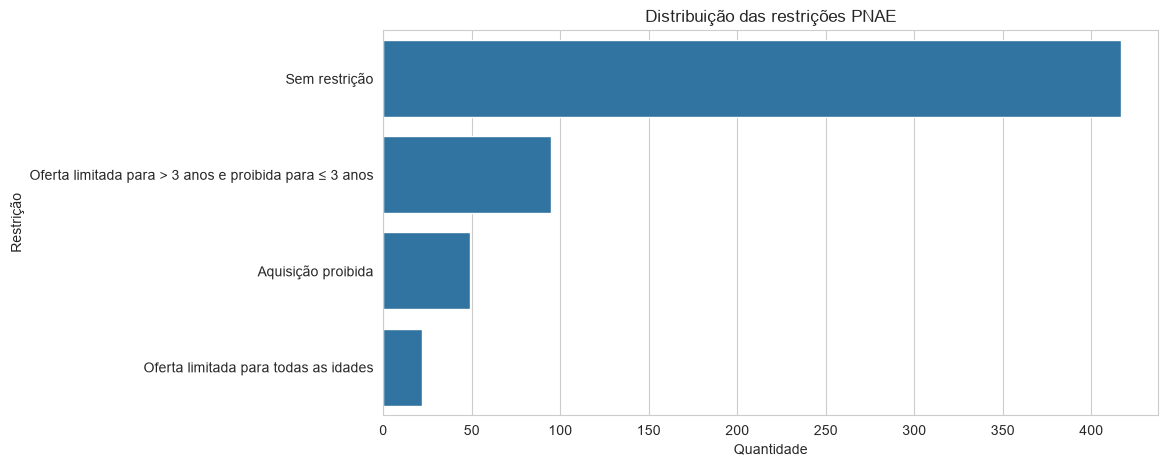

In [92]:
# Filtros simples

# Alimentos com aquisição proibida

df_proibidos = df[
    df["restricao_pnae"] == "Aquisição proibida"
]

print("\nQuantidade de alimentos proibidos:")
print(len(df_proibidos))


# Visualização das classificações

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    y="restricao_pnae",
    order=df["restricao_pnae"].value_counts().index
)

plt.title("Distribuição das restrições PNAE")

plt.xlabel("Quantidade")
plt.ylabel("Restrição")

plt.show()




In [93]:
# ═══════════════════════════════════════════════════════════════════════
# FILTRO: Itens sem preço unitário CONAB possível
# ═══════════════════════════════════════════════════════════════════════

PADROES_PREPARACAO = [
    r'\bc\/\s',                        # "c/ açúcar", "c/ sal"
    r'\be\s+\w+',                      # "abacaxi e banana"
    r'\b(suco|néctar|vitamina|sopa|caldo|salada|purê|mingau|mistura|ensopado|doce|bebida|geléia|diet|calda)\b',
    r'\b(cozid[ao]|assad[ao]|frit[ao]|refogad[ao]|grelhad[ao]|torrad[ao])\b',
    r'\b(desidratado|reconstituído|em\s+pó|instantâneo)\b',
    r'\b(pré.?cozido|semi.?pronto|pré.?preparo)\b',
]

# Lista de exclusão curada manualmente (cresce ao longo do projeto)
LISTA_EXCLUIR_MANUAL = {
    "abacaxi, banana e cenoura, suco natural (néctar), c/ açúcar refinado",
    # adicionar conforme identificado
}

def classificar_precificavel(nome: str) -> tuple[bool, str]:
    """
    Retorna (pode_precificar, motivo_exclusao).
    'pode_precificar' = False → excluir do matching de preços.
    """
    nome_lower = nome.lower() if isinstance(nome, str) else ""
    
    # Lista manual — máxima prioridade
    if nome_lower in {n.lower() for n in LISTA_EXCLUIR_MANUAL}:
        return False, "exclusao_manual"
    
    # Detecção automática de preparações compostas
    for padrao in PADROES_PREPARACAO:
        if re.search(padrao, nome_lower):
            return False, f"preparacao_detectada:{padrao}"
    
    return True, ""

df[['pode_precificar', 'motivo_exclusao']] = df['alimento'].apply(
    lambda x: pd.Series(classificar_precificavel(x))
)

# Relatório de transparência
excluidos = df[~df['pode_precificar']]
print(f"Itens excluídos do matching de preços: {len(excluidos)}")
print("\nMotivos:")
print(excluidos['motivo_exclusao'].value_counts())
print("\nItens excluídos (amostra):")
display(excluidos[['alimento', 'motivo_exclusao']].head(20))

# Salvar lista de excluídos para auditoria e curadoria
excluidos[['alimento', 'motivo_exclusao']].to_csv(
    output_folder + 'alimentos_sem_precificacao.csv',
    index=False, encoding='utf-8-sig'
)

Itens excluídos do matching de preços: 120

Motivos:
motivo_exclusao
preparacao_detectada:\b(suco|néctar|vitamina|sopa|caldo|salada|purê|mingau|mistura|ensopado|doce|bebida|geléia|diet|calda)\b    71
preparacao_detectada:\bc\/\s                                                                                                    18
preparacao_detectada:\b(cozid[ao]|assad[ao]|frit[ao]|refogad[ao]|grelhad[ao]|torrad[ao])\b                                      18
preparacao_detectada:\be\s+\w+                                                                                                   8
preparacao_detectada:\b(desidratado|reconstituído|em\s+pó|instantâneo)\b                                                         5
Name: count, dtype: int64

Itens excluídos (amostra):


,alimento,motivo_exclusao
1,"Abacaxi, banana e cenoura, suco natural (nécta...",preparacao_detectada:\bc\/\s
2,"Abacaxi, banana e cenoura, suco natural (nécta...",preparacao_detectada:\be\s+\w+
4,"Abacaxi, maracujá e caju, suco natural (néctar...",preparacao_detectada:\bc\/\s
5,"Abacaxi, melão e maracujá, suco natural (nécta...",preparacao_detectada:\bc\/\s
6,"Abacaxi, melão e maracujá, suco natural (nécta...",preparacao_detectada:\be\s+\w+
9,"Abacaxi, suco natural (néctar), c/ açúcar refi...",preparacao_detectada:\bc\/\s
10,"Abacaxi, suco natural (néctar), s/ açúcar",preparacao_detectada:\b(suco|néctar|vitamina|s...
20,"Açaí, polpa, com xarope de guaraná e glucose",preparacao_detectada:\be\s+\w+
25,"Acerola, suco natural (néctar), c/ açúcar refi...",preparacao_detectada:\bc\/\s
26,"Acerola, suco natural (néctar), s/ açúcar",preparacao_detectada:\b(suco|néctar|vitamina|s...


In [94]:
# Salvar o DataSet tratado

df.to_csv(
    output_folder+"dataset_pnae_com_restricoes.csv",
    index=False,
    encoding='utf-8-sig'
)


print("\nDataset salvo com sucesso.")


Dataset salvo com sucesso.


## Dados faltantes e imputação de dados
Dados faltantes são comuns e precisam ser tratados para evitar problemas em análises e modelagens.
Linhas ou colunas vazias já foram excluídas anteriormente.

In [95]:
print("\nDados faltantes por coluna:")
print(df.isnull().sum())


Dados faltantes por coluna:
alimento           0
energia            0
nan                0
proteina           0
lipideos           0
carboidratos       0
calcio             0
ferro              0
retinol            0
vitamina_c         0
sodio              0
restricao_pnae     0
pode_precificar    0
motivo_exclusao    0
dtype: int64


In [96]:
# Visualização dos dados faltantes
# Filtra e exibe as linhas com qualquer valor NaN ou None
linhas_com_nulos = df[df.isnull().any(axis=1)]

print("\nLinhas que contêm dados faltantes:")
print(linhas_com_nulos)


Linhas que contêm dados faltantes:
Empty DataFrame
Columns: [alimento, energia, nan, proteina, lipideos, carboidratos, calcio, ferro, retinol, vitamina_c, sodio, restricao_pnae, pode_precificar, motivo_exclusao]
Index: []


# Normalização Semântica e Estruturação

Esta seção implementa uma camada de normalização dos alimentos do PNAE para permitir:

- cruzamento com Painel de Preços (futuro)
- integração com PNCP (futuro)
- matching fuzzy
- padronização de produtos
- construção de dimensão de produtos

A abordagem evita utilizar a descrição textual completa como chave.

In [97]:
# Funções de normalização semântica

def ajustar_unidade_padrao(linha):
    
    #Avalia a descrição normalizada e o par (valor, unidade) extraído por regex.
    #Aplica a regra de unidade padrão baseada no tipo de produto.
    
    texto = str(linha['descricao_normalizada'])
    valor = linha['quantidade_embalagem']
    unidade = linha['unidade_medida']
    
    # Termos que obrigatoriamente devem ser tratados como Litro (l)
    termos_liquidos = {'suco', 'nectar', 'refrigerante', 'bebida', 'agua', 'mel', 'adocante', 'oleo', 'azeite', 'shoyu'}
    
    # Verifica se algum dos termos está contido no texto da descrição
    if any(termo in texto for termo in termos_liquidos):
        unidade_final = 'l'
    else:
        unidade_final = 'kg'
        
    # Se a regex não encontrou um valor numérico, retornamos None para o valor e a unidade padrão definida
    if pd.isna(valor) or valor is None:
        return pd.Series([None, unidade_final])
        
    return pd.Series([valor, unidade_final])


def remover_acentos(texto):
    if pd.isna(texto):
        return texto

    texto = unicodedata.normalize('NFD', str(texto))
    texto = ''.join(c for c in texto if unicodedata.category(c) != 'Mn')

    return texto


def normalizar_texto(texto):

    if pd.isna(texto):
        return ""

    texto = str(texto).lower()
    texto = remover_acentos(texto)

    texto = re.sub(r'[^a-z0-9\s]', ' ', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()

    return texto


# Termos irrelevantes para matching
stopwords_produtos = {
    'cru',
    'crua',
    'cozido',
    'cozida',
    'congelado',
    'congelada',
    'pacote',
    'pct',
    'caixa',
    'contendo',
    'produto',
    'alimenticio',
    'pronto',
    'pronta',
    'consumo',
    'embalagem',
    'grao',
    'salgado',
    'de qualquer marca',
    'artificial'
}


# Dicionário canônico inicial
dicionario_canonico = {
    'arroz integral': 'arroz integral',
    'arroz branco': 'arroz branco',
    'bebida lactea morango': 'bebida lactea morango',
    'banana prata': 'banana prata',
    'file de peixe': 'file de peixe'
}


def extrair_unidade(texto):

    texto = texto.lower()

    padroes = [
        (r'(\\d+(?:[\\.,]\\d+)?)\\s*kg', 'kg'),
        (r'(\\d+(?:[\\.,]\\d+)?)\\s*g', 'g'),
        (r'(\\d+(?:[\\.,]\\d+)?)\\s*l', 'l'),
        (r'(\\d+(?:[\\.,]\\d+)?)\\s*ml', 'ml')
    ]

    for padrao, unidade in padroes:
        match = re.search(padrao, texto)

        if match:
            valor = float(match.group(1).replace(',', '.'))
            return valor, unidade

    return None, None


def detectar_categoria(texto):

    categorias = {
        'biscoito_pao_bolo': ['biscoito', 'bolacha', 'pao', 'bolo', 'sonho'],
        'massas': ['massa', 'macarrao', 'espaguete', 'penne', 'fusilli', 'talharim', 'lasanha', 'pizza', 'nhoque', 'canelone', 'ravioli', 'pastel'],
        'sucos_bebidas': ['suco', 'refrigerante', 'bebida', 'agua', 'cha', 'polpa', 'cafe'],
        'doces_acucares': ['doce','geleia', 'mel', 'pudim', 'brigadeiro', 'cocada', 'goiabada', 'chocolate', 'mascavo', 'quindim','rapadura', 'pirulito', 'maria mole', 'acucar', 
                           'achocolatado', 'adocante','mingau', 'sagu', 'sorvete'],
        'gorduras_oleos': ['oleo', 'margarina', 'banha', 'azeite', 'manteiga'],
        'carneos': ['carne de sol', 'charque', 'linguica', 'mortadela', 'hamburguer', 'atum conserva', 'sardinha conserva', 'salsicha', 'salame', 'presunto', 'apresuntado',
                    'porquinho', 'toucinho', 'bacon', 'carne seca'],
        'cereais_tuberculos': ['cereais','arroz', 'aveia', 'milho', 'mandioca', 'batata', 'aipim', 'inhame', 'cara cru', 'macaxeira', 'cara', 'mandioquinha', 'batata doce', 
                               'farinha', 'fuba', 'polvilho', 'goma', 'tapioca', 'quinoa', 'cuscuz', 'trigo', 'centeio', 'canjica', 'farofa', 'pamonha', 'polenta', 'quirera'],
        'lacteos': ['leite', 'bebida lactea', 'iogurte', 'nata'],
        'frutas': ['banana', 'maca', 'laranja', 'mamao', 'melancia', 'abacaxi', 'manga', 'uva', 'tangerina', 'limao', 'goiaba', 'coco', 'pera', 'pessego', 'caqui', 'abacate', 'maracuja', 'melao', 'figo', 'acai','acerola',
                   'abiu','ameixa', 'araca', 'bacuri', 'cacau', 'caja', 'caju','carambola','ciriguela', 'cupuacu', 'graviola', 'jabuticaba', 'jaca', 'jambo', 'jenipapo', 'kiwi', 'mexerica', 'morango', 'nectarina', 'pequi', 'pinha',  
                   'pitanga', 'roma', 'sapoti', 'tamarindo', 'tapereba', 'tucuma', 'umbu', 'atemoia', 'butia', 'nectarina'],
        'legumes_verduras': ['abobora', 'abobrinha', 'berinjela', 'beterraba', 'brocolis', 'cenoura', 'chuchu', 'ervilha', 'inhame', 'jilo', 'pepino', 'pimentao', 'repolho', 'tomate', 'vagem', 'nabo', 
                    'palmito', 'amendoim grao', 'aspargo', 'alfafa', 'caruru', 'catalonha', 'jurubeba', 'manjericao', 'hortela', 'maxixe', 'palma', 'quiabo', 'rabanete', 'serralha',
                    'alface', 'agrião', 'almeirao', 'couve', 'espinafre', 'rucula', 'mostarda', 'acelga', 'escarola', 'repolho', 'brocolis', 'couve-flor', 'salsa', 'cebolinha', 'coentro', 'chicoria', 'endivia', 'taioba', 
                     'nabo', 'alho-poro', 'agriao', 'aipo', 'alfavaca'],
        'proteinas_animais': ['abadejo', 'almondega', 'atum', 'bacalhau', 'bisteca bovina', 'carne', 'caranguejo', 'camarao', 'cacao', 'corimba', 'corvina', 'dourada', 'feijao', 'feijao-verde', 'frango', 'grao-de-bico', 'grao de bico', 'guandu', 
                      'lambari', 'leite', 'lentilha', 'mocoto', 'moela', 'ovo', 'peixe', 'galinha', 'peru', 'pescada', 'pescadinha', 'porco', 'queijo', 'salmao', 'sardinha', 'soja', 'tofu', 
                      'tremoço', 'atum', 'viscera bovina', 'merluza', 'pintado', 'tucunare', 'fava','tremoco'],
        'oleaginosas_sementes': ['castanha', 'noz', 'amendoim', 'linhaca', 'chia', 'amendoa', 'pistache', 'macadamia', 'avela','gergelim'],
        'condimentos': ['sal', 'pimenta', 'tempero', 'ervas', 'alho', 'cebola','louro', 'canela', 'cravo', 'cominho', 'acafrao', 'curcuma', 'alecrim', 'tomilho', 'oregano'],
        'conservas': ['conserva', 'picles', 'compota'],
        'outros_industrializados': ['barra de cereais', 'chantilly', 'fermento', 'gelatina', 'sopa desidratada', 'industrializado', 'enlatado', 'shoyu', 'sagu mistura', 'mingau tradicional po', 'farofa', 'enlatada', 'enlatado']
    }

    for categoria, termos in categorias.items():
        for termo in termos:
            if termo in texto:
                return categoria

    return 'nao_classificado'

def extrair_produto_base(texto):

    texto = normalizar_texto(texto)

    tokens = [
        t for t in texto.split()
        if t not in stopwords_produtos
    ]

    texto_limpo = ' '.join(tokens)

    # Matching exato via dicionário
    for chave in dicionario_canonico.keys():
        if chave in texto_limpo:
            return dicionario_canonico[chave]

    # Fallback fuzzy
    resultado = process.extractOne(
        texto_limpo,
        list(dicionario_canonico.keys()),
        scorer=fuzz.token_sort_ratio
    )

    if resultado:
        nome, score, _ = resultado

        if score >= 85:
            return dicionario_canonico[nome]

    return texto_limpo

In [98]:
# Localizar automaticamente coluna de descrição do alimento

colunas_possiveis = [
    col for col in df.columns
    if 'alimento' in str(col).lower()
    or 'descricao' in str(col).lower()
]

print('Colunas candidatas:')
print(colunas_possiveis)

# Selecionar primeira coluna compatível
coluna_descricao = colunas_possiveis[0]

print(f'\\nColuna utilizada: {coluna_descricao}')


# Criar camada semântica estruturada

df['descricao_normalizada'] = (
    df[coluna_descricao]
    .astype(str)
    .apply(normalizar_texto)
)

df['produto_base'] = (
    df['descricao_normalizada']
    .apply(extrair_produto_base) 
)

df['categoria'] = (
    df['descricao_normalizada']
    .apply(detectar_categoria)
)

# Extração preliminar via Regex (Valores numéricos e unidades textuais originais)
df[['quantidade_embalagem', 'unidade_medida']] = (
    df['descricao_normalizada']
    .apply(lambda x: pd.Series(extrair_unidade(x)))
)

# Aplicação da regra de negócio para unidades de medida (Litro vs Quilo)
df[['quantidade_embalagem', 'unidade_medida']] = df.apply(ajustar_unidade_padrao, axis=1)


# Exemplo de estrutura normalizada
print('\\nExemplo de estrutura normalizada:')
display(
    df[
        [
            coluna_descricao,
            'descricao_normalizada',
            'produto_base',
            'categoria',
            'quantidade_embalagem',
            'unidade_medida'
        ]
    ].head(30)
)

Colunas candidatas:
['alimento']
\nColuna utilizada: alimento
\nExemplo de estrutura normalizada:


,alimento,descricao_normalizada,produto_base,categoria,quantidade_embalagem,unidade_medida
0,"Abacate, cru",abacate cru,abacate,frutas,NaN,kg
1,"Abacaxi, banana e cenoura, suco natural (nécta...",abacaxi banana e cenoura suco natural nectar c...,abacaxi banana e cenoura suco natural nectar c...,sucos_bebidas,NaN,l
2,"Abacaxi, banana e cenoura, suco natural (nécta...",abacaxi banana e cenoura suco natural nectar s...,abacaxi banana e cenoura suco natural nectar s...,sucos_bebidas,NaN,l
3,"Abacaxi, cru",abacaxi cru,abacaxi,frutas,NaN,kg
4,"Abacaxi, maracujá e caju, suco natural (néctar...",abacaxi maracuja e caju suco natural nectar c ...,abacaxi maracuja e caju suco natural nectar c ...,sucos_bebidas,NaN,l
5,"Abacaxi, melão e maracujá, suco natural (nécta...",abacaxi melao e maracuja suco natural nectar c...,abacaxi melao e maracuja suco natural nectar c...,sucos_bebidas,NaN,l
6,"Abacaxi, melão e maracujá, suco natural (nécta...",abacaxi melao e maracuja suco natural nectar s...,abacaxi melao e maracuja suco natural nectar s...,sucos_bebidas,NaN,l
7,"Abacaxi, polpa, congelada",abacaxi polpa congelada,abacaxi polpa,sucos_bebidas,NaN,kg
8,"Abacaxi, polpa, congelada",abacaxi polpa congelada,abacaxi polpa,sucos_bebidas,NaN,kg
9,"Abacaxi, suco natural (néctar), c/ açúcar refi...",abacaxi suco natural nectar c acucar refinado,abacaxi suco natural nectar c acucar refinado,sucos_bebidas,NaN,l


In [99]:
# Construção da dimensão canônica de produtos

dim_produtos = (
    df[
        [
            'produto_base',
            'categoria',
            'unidade_medida'
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

dim_produtos['id_produto'] = (
    dim_produtos.index + 1000
)

dim_produtos = dim_produtos[
    [
        'id_produto',
        'produto_base',
        'categoria',
        'unidade_medida'
    ]
]

print('Dimensão de produtos:')
display(dim_produtos.head(20))

Dimensão de produtos:


,id_produto,produto_base,categoria,unidade_medida
0,1000,abacate,frutas,kg
1,1001,abacaxi banana e cenoura suco natural nectar c...,sucos_bebidas,l
2,1002,abacaxi banana e cenoura suco natural nectar s...,sucos_bebidas,l
3,1003,abacaxi,frutas,kg
4,1004,abacaxi maracuja e caju suco natural nectar c ...,sucos_bebidas,l
5,1005,abacaxi melao e maracuja suco natural nectar c...,sucos_bebidas,l
6,1006,abacaxi melao e maracuja suco natural nectar s...,sucos_bebidas,l
7,1007,abacaxi polpa,sucos_bebidas,kg
8,1008,abacaxi suco natural nectar c acucar refinado,sucos_bebidas,l
9,1009,abacaxi suco natural nectar s acucar,sucos_bebidas,l


In [100]:
# Exportação para futuras integrações com Painel de Preços / PNCP / BI

df.to_csv(
    output_folder + 'pnae_alimentos_normalizados.csv',
    index=False,
    encoding='utf-8-sig'
)

dim_produtos.to_csv(
    output_folder + 'dim_produtos_pnae.csv',
    index=False,
    encoding='utf-8-sig'
)

print('Arquivos exportados:')
print('- pnae_alimentos_normalizados.csv')
print('- dim_produtos_pnae.csv')

Arquivos exportados:
- pnae_alimentos_normalizados.csv
- dim_produtos_pnae.csv


In [101]:
display(df.head())

,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae,pode_precificar,motivo_exclusao,descricao_normalizada,produto_base,categoria,quantidade_embalagem,unidade_medida
0,"Abacate, cru",96.154709,402.3113011826088,1.239130,8.396667,6.030870,7.916667,0.206667,61.2,8.660000,0.00,Sem restrição,True,,abacate cru,abacate,frutas,NaN,kg
1,"Abacaxi, banana e cenoura, suco natural (nécta...",64.000000,267.776,0.570000,0.140000,15.700000,10.500000,0.260000,235.0,7.960000,5.19,Oferta limitada para > 3 anos e proibida para ...,False,preparacao_detectada:\bc\/\s,abacaxi banana e cenoura suco natural nectar c...,abacaxi banana e cenoura suco natural nectar c...,sucos_bebidas,NaN,l
2,"Abacaxi, banana e cenoura, suco natural (nécta...",28.000000,117.152,0.610000,0.150000,6.590000,11.300000,0.280000,261.0,8.820000,4.43,Sem restrição,False,preparacao_detectada:\be\s+\w+,abacaxi banana e cenoura suco natural nectar s...,abacaxi banana e cenoura suco natural nectar s...,sucos_bebidas,NaN,l
3,"Abacaxi, cru",48.322213,202.18013937391297,0.858696,0.123333,12.334638,22.433333,0.256667,2.3,34.623333,0.00,Sem restrição,True,,abacaxi cru,abacaxi,frutas,NaN,kg
4,"Abacaxi, maracujá e caju, suco natural (néctar...",70.000000,292.88,0.550000,0.230000,16.700000,9.470000,0.330000,22.3,53.000000,14.50,Oferta limitada para > 3 anos e proibida para ...,False,preparacao_detectada:\bc\/\s,abacaxi maracuja e caju suco natural nectar c ...,abacaxi maracuja e caju suco natural nectar c ...,sucos_bebidas,NaN,l


## Cálculo do Score de Densidade Nutricional (SDN)
Alimentos com alto SDN são escolhas de excelência para o PNAE, pois combatem a desnutrição de micronutrientes sem exceder o limite calórico diário.

Esta estrutura permite que sua Programação Linear selecione não apenas o "mais barato", mas o que possui maior SDN dentro do orçamento, elevando a qualidade nutricional da merenda escolar.

"As faixas de referência para micronutrientes são destacadas especialmente para crianças em creche (0 a 3 anos) devido à maior vulnerabilidade dessa faixa etária. Nessa fase, o crescimento edesenvolvimento são intensos, e a oferta adequada de vitaminas e minerais essenciais, como ferro, vitamina A e cálcio, é fundamental para prevenir deficiências nutricionais e garantir a saúde e o desenvolvimento adequado das crianças." (RESOLUÇÃO CD/FNDE Nº 4, DE 26 DE FEVEREIRO DE 2026) Não há no PNAE a definição da proporção de consumo de micronutrientes para as demais faixas. No modelo, por simplificação, estamos adotando a faixa de alunos > 3 anos. 

**REVISAR/VALIDAR O CÁLCULO E PESO** 
1/4 PARA CADA MICRONUTRIENTE É UMA SIMPLIFICAÇÃO


In [102]:
# Normalizando micronutrientes (0 a 1) para compor o score
# Isso evita que um nutriente com escala maior (ex: Cálcio) domine o score sobre o Ferro
for col in ['calcio', 'ferro', 'retinol', 'vitamina_c']:
    df[f'norm_{col}'] = (df[col] - df[col].min()) / (df[col].max() - df[col].min())

# Cálculo do SDN (Score de Densidade Nutricional)
# SDN = Soma dos nutrientes normalizados / Energia (kcal)
# Onde quanto maior o SDN, mais nutritivo por caloria o alimento é.
df['sdn_score'] = (df['norm_calcio'] + df['norm_ferro'] + df['norm_retinol'] + df['norm_vitamina_c']) / (df['energia'] + 1)

# Ranking de densidade nutricional
top_densidade = df.nlargest(10, 'sdn_score')[['alimento', 'sdn_score', 'categoria']]

# Métricas de Eficiência e Score de Densidade
df['relacao_proteina_caloria'] = df['proteina'] / (df['energia'] + 0.01)


## Estado de preparo dos alimentos

In [103]:
# Função para Normalizar o Estado de Preparo
def identificar_estado_preparo(texto):
    if not isinstance(texto, str): return "nao_identificado"
    texto = texto.lower()
    estados = {
        'cru': [r'\bcru\b', r'\bcrua\b'],
        'cozido': [r'\bcozido\b', r'\bcozida\b', r'\bcoz\b'],
        'congelado': [r'\bcongelado\b', r'\bcongelada\b'],
        'polpa': [r'\bpolpa\b'],
        'suco_nectar': [r'\bsuco\b', r'\bnectar\b'],
        'desidratado_po': [r'\bpo\b', r'\bdesidratado\b', r'\bfarinha\b'],
        'conserva': [r'\bconserva\b', r'\benlatado\b'],
        'assado_grelhado': [r'\bassado\b', r'\bgrelhado\b']
    }
    for estado, padroes in estados.items():
        for padrao in padroes:
            if re.search(padrao, texto): return estado
    return "natural_ou_outros"

df['estado_preparo'] = df['descricao_normalizada'].apply(identificar_estado_preparo)



# Análises
## Análises nutricionais

In [104]:
print("--- ANÁLISES NUTRICIONAIS (Top 10 Alimentos) ---")

# Filtro para comparação justa: Apenas alimentos no estado Cru
df_cru = df[df['estado_preparo'] == 'cru']

print("\n1. Maior teor de proteína (Cru):")
display(df_cru.nlargest(10, 'proteina')[['alimento', 'proteina']])

print("\n2. Menor densidade energética (Geral):")
display(df.nsmallest(10, 'energia')[['alimento', 'energia']])

print("\n3. Maior teor de sódio (Alerta PNAE):")
display(df.nlargest(10, 'sodio')[['alimento', 'sodio', 'restricao_pnae']])

print("\n4. Maior concentração de micronutrientes (Cálcio e Ferro):")
print("\n4.1 Cálcio:")
display(df_cru.nlargest(10, 'calcio')[['alimento', 'calcio']])
print("\n4.2 Ferro:")
display(df_cru.nlargest(10, 'ferro')[['alimento', 'ferro']])

print("\n5. Melhor relação Proteína/Caloria:")
display(df.nlargest(10, 'relacao_proteina_caloria')[['alimento', 'relacao_proteina_caloria']])

print("\n6. Alta Densidade Nutricional (SDN Score):")
display(df.nlargest(10, 'sdn_score')[['alimento', 'sdn_score', 'categoria']])

# 7. Médias por Categoria
print("\n7. Média de Calorias por Grupo Alimentar:")
display(df.groupby('categoria')['energia'].mean().sort_values(ascending=False))

# 8. Correlação
corr = df['energia'].corr(df['lipideos'])
print(f"\n8. Correlação entre Calorias e Lipídeos: {corr:.2f}")

--- ANÁLISES NUTRICIONAIS (Top 10 Alimentos) ---

1. Maior teor de proteína (Cru):


,alimento,proteina
566,"Tremoço, cru",33.575000
138,"Carne, avestruz, crua (média de diferentes cor...",30.100000
67,"Bacalhau, salgado, cru",29.036667
50,"Amendoim, grão, cru",27.190800
61,"Atum, fresco, cru",25.680000
148,"Carne, bovina, contra-filé, sem gordura, cru",23.996667
347,"Lentilha, crua",23.152174
145,"Carne, bovina, charque, cru",22.714583
494,"Porco, lombo, cru",22.604167
253,"Feijão, roxo, cru",22.166667



2. Menor densidade energética (Geral):


,alimento,energia
32,Adoçante artificial,0.000000
303,"Iogurte, sabor abacaxi",0.000000
526,"Sal, dietético",0.000000
527,"Sal, grosso",0.000000
109,Café,1.000000
186,"Chá (preto, camomila, erva-cidreira, capim-lim...",1.000000
293,Hortelã,1.000000
187,Chá mate orgânico,2.800000
26,"Acerola, suco natural (néctar), s/ açúcar",7.000000
36,"Alface, americana, crua",8.794903



3. Maior teor de sódio (Alerta PNAE):


,alimento,sodio,restricao_pnae
527,"Sal, grosso",39943.000000,Sem restrição
554,Tempero a base de sal,32560.000000,Aquisição proibida
526,"Sal, dietético",23432.000000,Sem restrição
121,"Caldo de galinha, tablete",22300.000000,Aquisição proibida
120,"Caldo de carne, tablete",22180.000000,Aquisição proibida
67,"Bacalhau, salgado, cru",13585.056667,Sem restrição
255,"Fermento em pó, químico",10052.000000,Sem restrição
145,"Carne, bovina, charque, cru",5875.000000,Sem restrição
540,Shoyu,5064.000000,Aquisição proibida
416,"Molho, soja, shoyu",5025.000000,Aquisição proibida


... (7 outputs left out)

,alimento,sdn_score,categoria
524,"Rúcula, crua",0.053598,legumes_verduras
26,"Acerola, suco natural (néctar), s/ açúcar",0.042755,sucos_bebidas
23,"Acerola, crua",0.029330,frutas
24,"Acerola, polpa, congelada",0.029217,sucos_bebidas
396,"Melancia e acerola, suco natural (nectar), s/ ...",0.013463,sucos_bebidas
25,"Acerola, suco natural (néctar), c/ açúcar refi...",0.012076,sucos_bebidas
33,"Agrião, cru",0.010438,legumes_verduras
171,"Caruru, cru",0.010210,legumes_verduras
306,"Iogurte, soja (média de diferentes amostras)",0.009719,lacteos
533,Salsinha,0.008024,condimentos



7. Média de Calorias por Grupo Alimentar:


categoria
nao_classificado           900.000000
gorduras_oleos             683.102342
oleaginosas_sementes       564.816291
biscoito_pao_bolo          367.852880
cereais_tuberculos         290.323320
massas                     285.757382
doces_acucares             276.699303
carneos                    260.986875
outros_industrializados    214.275170
proteinas_animais          208.665555
condimentos                175.533417
conservas                  165.545139
lacteos                    136.257791
frutas                     103.531600
sucos_bebidas               65.356200
legumes_verduras            49.975127
Name: energia, dtype: float64


8. Correlação entre Calorias e Lipídeos: 0.51


## Análise por grupos alimentares

In [105]:

print("--- ANÁLISE POR GRUPOS ALIMENTARES ---")

# 1. Contagem e Variedade por Grupo
contagem_grupos = df['categoria'].value_counts()
print("\n1. Quantidade de alimentos por grupo (Variedade):")
display(contagem_grupos)

# 2. Média de Sódio por Grupo
print("\n2. Grupos com maior média de Sódio (mg/100g):")
sodio_por_grupo = df.groupby('categoria')['sodio'].mean().sort_values(ascending=False)
display(sodio_por_grupo.head(5))

# 3. Grupos mais Energéticos (Kcal)
print("\n3. Grupos com maior densidade energética média (kcal/100g):")
energia_por_grupo = df.groupby('categoria')['energia'].mean().sort_values(ascending=False)
display(energia_por_grupo.head(5))

# 4. Riqueza em Ferro (Média do grupo)
print("\n4. Grupos com maior concentração média de Ferro:")
ferro_por_grupo = df.groupby('categoria')['ferro'].mean().sort_values(ascending=False)
display(ferro_por_grupo.head(5))

# 5. Concentração de Alimentos Restritos/Proibidos por Grupo
# Filtramos apenas os alimentos com restrição ativa
print("\n5. Grupos com maior concentração de alimentos 'Aquisição proibida':")
restritos_por_grupo = df[df['restricao_pnae'] == 'Aquisição proibida'].groupby('categoria').size().sort_values(ascending=False)
display(restritos_por_grupo)

# 6. Predominância: Origem Vegetal vs Animal
# Criando uma lógica de origem baseada nas categorias mapeadas
origem_map = {
    'proteinas_animais': 'Animal', 'carneos': 'Animal', 'lacteos': 'Animal',
    'frutas': 'Vegetal', 'legumes_verduras': 'Vegetal', 'cereais_tuberculos': 'Vegetal',
    'oleaginosas_sementes': 'Vegetal', 'massas': 'Vegetal' # Simplificação para análise
}
df['origem'] = df['categoria'].map(origem_map).fillna('Outros/Processados')

print("\n6. Predominância de origem no cadastro:")
display(df['origem'].value_counts(normalize=True) * 100) # Em percentual

--- ANÁLISE POR GRUPOS ALIMENTARES ---

1. Quantidade de alimentos por grupo (Variedade):


categoria
proteinas_animais          122
frutas                      80
sucos_bebidas               79
legumes_verduras            64
cereais_tuberculos          57
doces_acucares              56
biscoito_pao_bolo           27
lacteos                     23
gorduras_oleos              20
condimentos                 14
carneos                     14
oleaginosas_sementes         8
outros_industrializados      8
massas                       8
conservas                    2
nao_classificado             1
Name: count, dtype: int64


2. Grupos com maior média de Sódio (mg/100g):


categoria
condimentos                6960.509214
outros_industrializados    2904.517083
conservas                  1457.000000
carneos                     966.071429
proteinas_animais           736.889027
Name: sodio, dtype: float64


3. Grupos com maior densidade energética média (kcal/100g):


categoria
nao_classificado        900.000000
gorduras_oleos          683.102342
oleaginosas_sementes    564.816291
biscoito_pao_bolo       367.852880
cereais_tuberculos      290.323320
Name: energia, dtype: float64

... (2 outputs left out)


5. Grupos com maior concentração de alimentos 'Aquisição proibida':


categoria
doces_acucares             14
cereais_tuberculos          9
biscoito_pao_bolo           7
outros_industrializados     5
proteinas_animais           4
legumes_verduras            3
gorduras_oleos              2
condimentos                 2
sucos_bebidas               2
nao_classificado            1
dtype: int64


6. Predominância de origem no cadastro:


origem
Vegetal               37.221269
Outros/Processados    35.506003
Animal                27.272727
Name: proportion, dtype: float64

## Análises das restrições do PNAE
Veja no 3. Comparativo Nutricional: alimentos classificados como 'Aquisição Proibida' geralmente apresentam uma correlação direta com alto teor de sódio e/ou carboidratos refinados. 

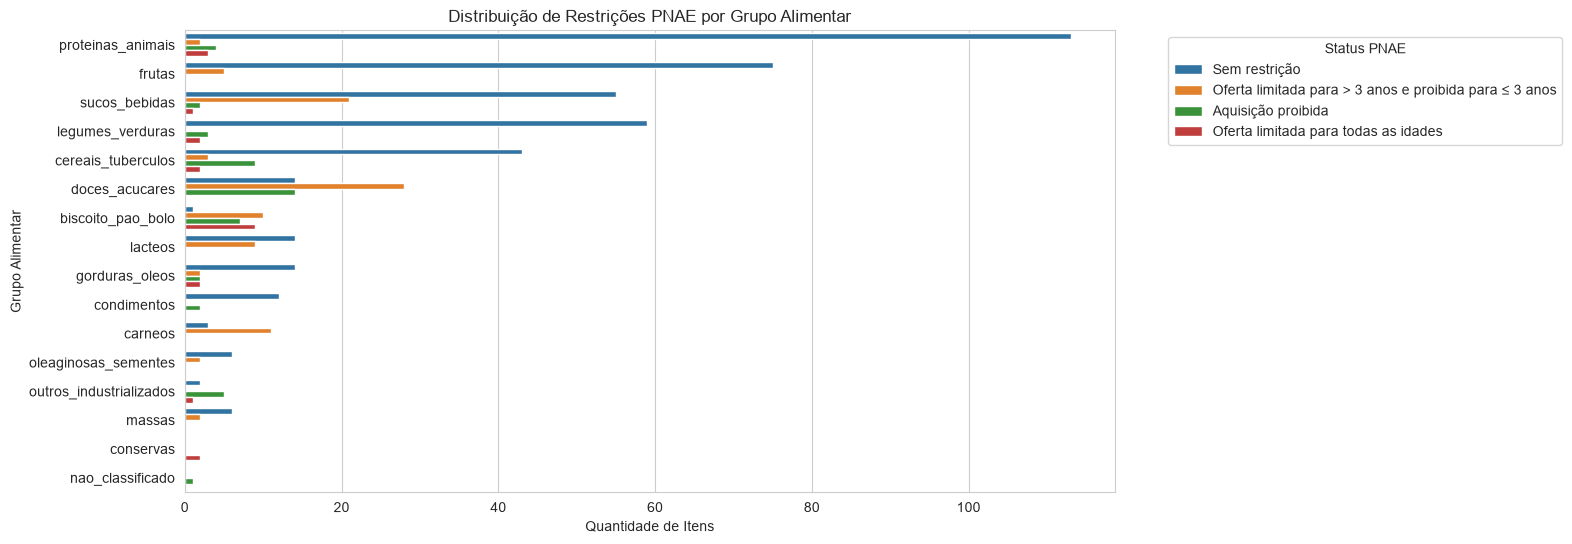

--- ANÁLISE DE RESTRIÇÕES PNAE ---

Total de alimentos no banco: 583

Distribuição por tipo de restrição:
- Sem restrição: 417 (71.53%)
- Oferta limitada para > 3 anos e proibida para ≤ 3 anos: 95 (16.30%)
- Aquisição proibida: 49 (8.40%)
- Oferta limitada para todas as idades: 22 (3.77%)

Grupos com maior concentração de itens restritos:


categoria
doces_acucares             42
biscoito_pao_bolo          26
sucos_bebidas              24
cereais_tuberculos         14
carneos                    11
proteinas_animais           9
lacteos                     9
gorduras_oleos              6
outros_industrializados     6
frutas                      5
legumes_verduras            5
conservas                   2
condimentos                 2
oleaginosas_sementes        2
massas                      2
nao_classificado            1
Name: count, dtype: int64


Comparação de médias nutricionais (Restrito vs. Não Restrito):


,energia,sodio,carboidratos,lipideos
is_restrito,,,,
False,172.568648,316.779142,17.122700,8.398935
True,269.716305,908.183806,39.352728,14.160183



Top 10 alimentos restritos com maior teor de sódio:


,alimento,sodio,categoria
554,Tempero a base de sal,32560.0,condimentos
121,"Caldo de galinha, tablete",22300.0,proteinas_animais
120,"Caldo de carne, tablete",22180.0,proteinas_animais
540,Shoyu,5064.0,outros_industrializados
416,"Molho, soja, shoyu",5025.0,proteinas_animais
546,Sopa desidratada (média diferentes sabores),3645.0,outros_industrializados
547,"Sopa, desidratada, (média diferentes sabores)",3645.0,outros_industrializados
567,"Tremoço, em conserva",1809.0,proteinas_animais
501,"Pudim, mistura p/, diet (média diferentes sabo...",1794.0,doces_acucares
528,Salame,1574.0,carneos



Sugestão de alternativas para 'Farofa pronta':


,alimento,sdn_score,proteina,energia
131,"Caranguejo, cozido",0.003056,18.479167,82.721502
130,"Carambola, crua",0.001501,0.870833,45.740889
232,"Farinha, de arroz, enriquecida",0.001389,1.269333,363.056480


In [106]:
# Onde estão os gargalos do PNAE no dataset
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='categoria', hue='restricao_pnae', 
              order=df['categoria'].value_counts().index)
plt.title('Distribuição de Restrições PNAE por Grupo Alimentar')
plt.xlabel('Quantidade de Itens')
plt.ylabel('Grupo Alimentar')
plt.legend(title='Status PNAE', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


print("--- ANÁLISE DE RESTRIÇÕES PNAE ---")

# 1. Quantitativo e Percentual
total_alimentos = len(df)
contagem_restricao = df['restricao_pnae'].value_counts()
percentual_restricao = (contagem_restricao / total_alimentos) * 100

print(f"\nTotal de alimentos no banco: {total_alimentos}")
print("\nDistribuição por tipo de restrição:")
for status, qtd in contagem_restricao.items():
    print(f"- {status}: {qtd} ({percentual_restricao[status]:.2f}%)")

# 2. Grupos com mais itens restritos (Aquisição Proibida ou Oferta Limitada)
# Consideramos 'Restritos' tudo que não é 'Sem restrição'
df_restritos_all = df[df['restricao_pnae'] != 'Sem restrição']
print("\nGrupos com maior concentração de itens restritos:")
display(df_restritos_all['categoria'].value_counts())

# 3. Comparativo Nutricional: Restritos vs. Não Restritos
# Criamos uma flag para facilitar a comparação
df['is_restrito'] = df['restricao_pnae'] != 'Sem restrição'

comparativo_nutricional = df.groupby('is_restrito')[['energia', 'sodio', 'carboidratos', 'lipideos']].mean()
print("\nComparação de médias nutricionais (Restrito vs. Não Restrito):")
display(comparativo_nutricional)

# 4. Investigação de Açúcares e Sódio
# No dataset PNAE, carboidratos altos em 'Aquisição Proibida' (doces/sucos) costumam indicar açúcares livres.
print("\nTop 10 alimentos restritos com maior teor de sódio:")
display(df_restritos_all.nlargest(10, 'sodio')[['alimento', 'sodio', 'categoria']])

# 5. Busca por Alternativas Equivalentes
# Exemplo: Se um alimento é restrito, buscamos na mesma categoria um 'Sem restrição' com SDN alto.
def sugerir_alternativa(alimento_nome):
    row = df[df['alimento'] == alimento_nome].iloc[0]
    cat = row['categoria']
    
    alternativas = df[
        (df['categoria'] == cat) & 
        (df['restricao_pnae'] == 'Sem restrição')
    ].nlargest(3, 'sdn_score')
    
    return alternativas[['alimento', 'sdn_score', 'proteina', 'energia']]

# Teste de exemplo
print("\nSugestão de alternativas para 'Farofa pronta':")
display(sugerir_alternativa('Farofa pronta'))
# Nota: use o nome exato do seu df['alimento'] para testar a função

Distribuição de restrições por categoria:


restricao_pnae,Aquisição proibida,Oferta limitada para > 3 anos e proibida para ≤ 3 anos,Oferta limitada para todas as idades,Sem restrição,All
categoria,,,,,
All,49,95,22,417,583
proteinas_animais,4,2,3,113,122
frutas,0,5,0,75,80
sucos_bebidas,2,21,1,55,79
legumes_verduras,3,0,2,59,64
cereais_tuberculos,9,3,2,43,57
doces_acucares,14,28,0,14,56
biscoito_pao_bolo,7,10,9,1,27
lacteos,0,9,0,14,23


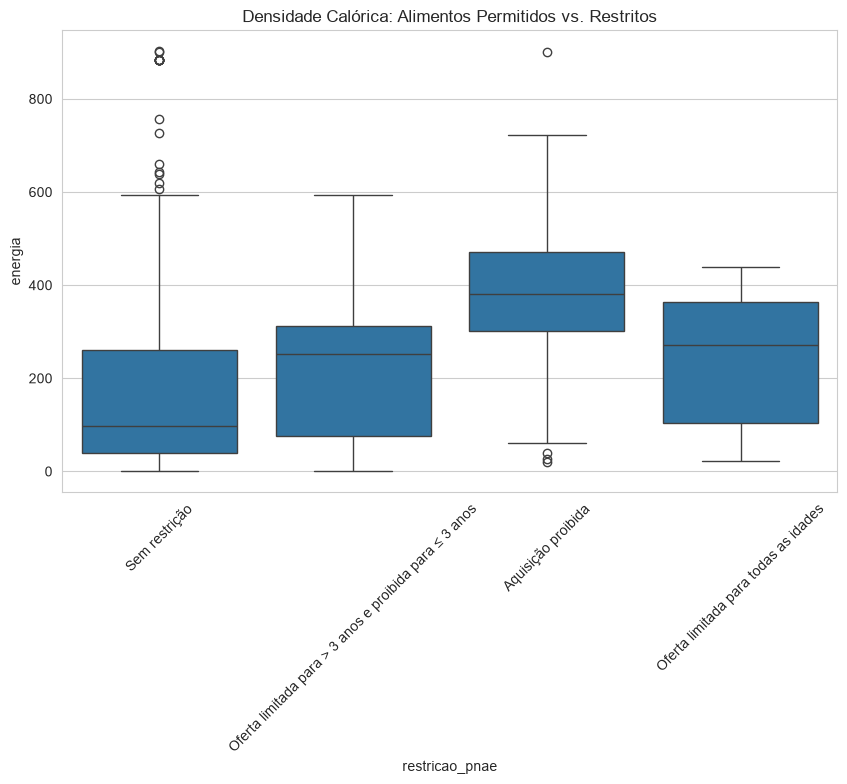

In [107]:
# Cruzamento Categoria x Restrição
print("Distribuição de restrições por categoria:")
dist_restricao = pd.crosstab(df['categoria'], df['restricao_pnae'], margins=True).sort_values(by='All', ascending=False)
display(dist_restricao)

# Visualização de Densidade Calórica
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='restricao_pnae', y='energia')
plt.title('Densidade Calórica: Alimentos Permitidos vs. Restritos')
plt.xticks(rotation=45)
plt.show()

## Correlação nutricional
### Correlações: variáveis numéricas e categóricas
Correlações medem a relação entre variáveis. Para variáveis numéricas, usa-se a correlação de Pearson; para categóricas, o Cramér's V.

Energia vs. Lipídeos: Você notará uma correlação positiva forte, confirmando que a gordura é o principal driver calórico neste dataset do PNAE.

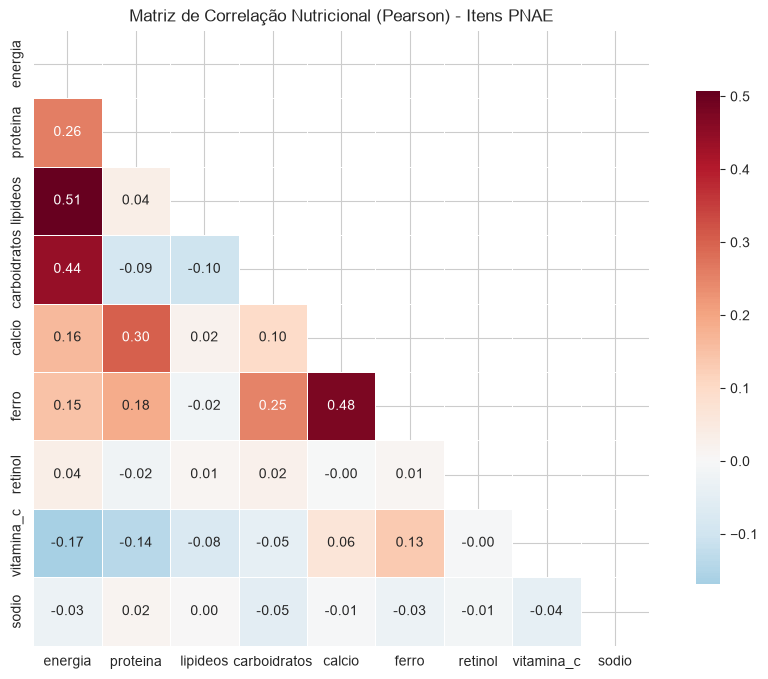

In [108]:
# Selecionando apenas as colunas nutricionais relevantes
cols_nutricionais = [
    'energia', 'proteina', 'lipideos', 'carboidratos', 
    'calcio', 'ferro', 'retinol', 'vitamina_c', 'sodio'
]

# Calculando a matriz de correlação de Pearson
corr_matrix = df[cols_nutricionais].corr()

# Gerando o Heatmap
plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Máscara para ver apenas metade (evita redundância)

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt=".2f", 
    cmap='RdBu_r', 
    center=0,
    square=True, 
    linewidths=.5, 
    cbar_kws={"shrink": .8}
)

plt.title('Matriz de Correlação Nutricional (Pearson) - Itens PNAE')
plt.show()

## Outliers
Outliers são valores que se desviam significativamente da maioria dos dados.

Na nutrição, a maioria dos outliers é real e biológica. Por exemplo, o retinol (Vitamina A) terá outliers extremos causados por vísceras (fígado), enquanto o sódio terá outliers causados por temperos e conservas.

Para o modelo de otimização, NÃO removeremos os outliers, pois eles representam as melhores fontes de nutrientes específicos. O objetivo do IQR aqui é puramente de diagnóstico e validação da integridade dos dados.

Se o Sódio tiver muitos outliers superiores em itens de "Aquisição Proibida", isso valida estatisticamente as restrições impostas pelo FNDE.

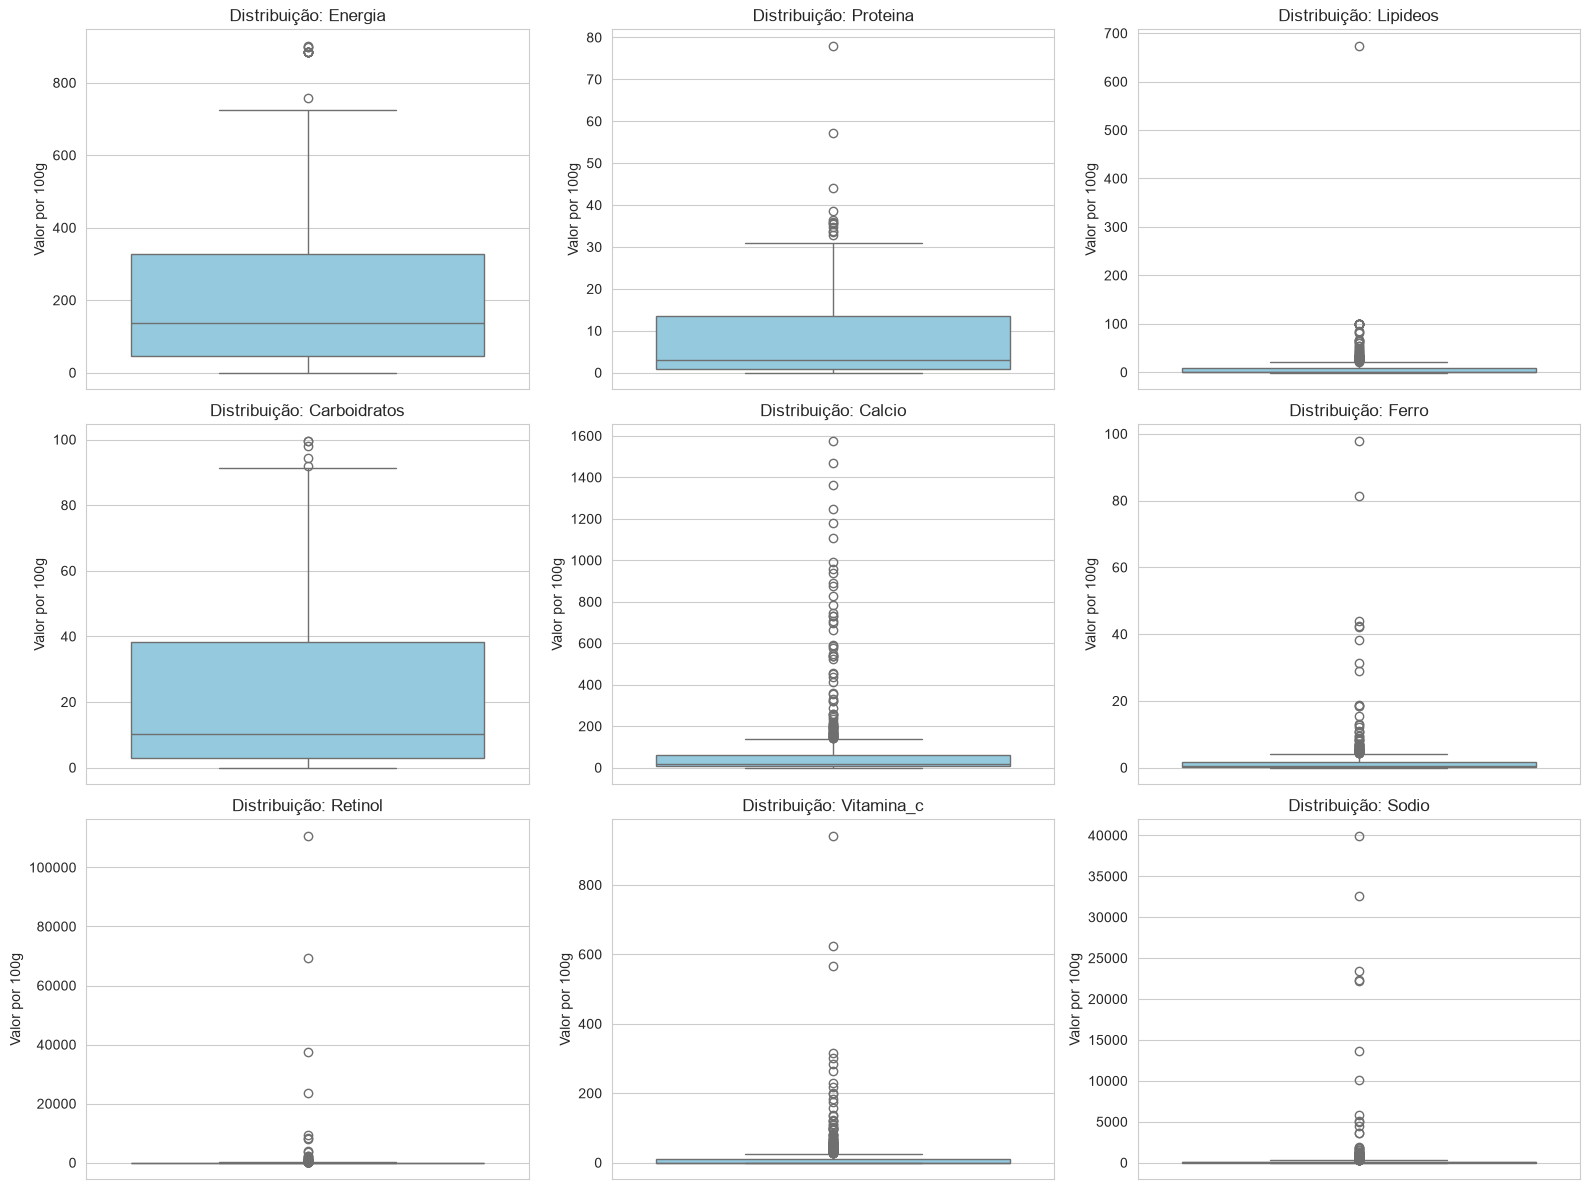

--- RESUMO DE OUTLIERS IDENTIFICADOS ---


,Atributo,Q1,Q3,IQR,Limite_Sup,Qtd_Outliers,Perc_Outliers
0,energia,47.000000,326.952633,279.952633,746.881583,12,2.058319
1,proteina,0.831667,13.568750,12.737083,32.674375,12,2.058319
2,lipideos,0.168333,8.835000,8.666667,21.835000,73,12.521441
3,carboidratos,2.857667,38.419950,35.562283,91.763375,5,0.857633
4,calcio,6.506333,59.976167,53.469833,140.180917,73,12.521441
5,ferro,0.170000,1.760000,1.590000,4.145000,59,10.120069
6,retinol,0.000000,30.000000,30.000000,75.000000,93,15.951973
7,vitamina_c,0.000000,10.494500,10.494500,26.236250,91,15.608919
8,sodio,1.616833,127.036667,125.419833,315.166417,112,19.210978


In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

cols_analise = ['energia', 'proteina', 'lipideos', 'carboidratos', 'calcio', 'ferro', 'retinol', 'vitamina_c', 'sodio']
resumo_outliers = []

plt.figure(figsize=(16, 12))

for i, col in enumerate(cols_analise):
    # Cálculo do IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Identificando Outliers
    outliers = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]
    
    resumo_outliers.append({
        'Atributo': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Limite_Sup': limite_superior,
        'Qtd_Outliers': len(outliers),
        'Perc_Outliers': (len(outliers) / len(df)) * 100
    })
    
    # Visualização com Boxplot
    plt.subplot(3, 3, i+1)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Distribuição: {col.capitalize()}')
    plt.ylabel('Valor por 100g')

plt.tight_layout()
plt.show()

# Exibição do resumo estatístico
df_resumo_outliers = pd.DataFrame(resumo_outliers)
print("--- RESUMO DE OUTLIERS IDENTIFICADOS ---")
display(df_resumo_outliers)

## Planejamento e metas nutricionais

In [110]:
# 1. Metas de Proteína (Custo Metabólico Eficiente)
print("1. Melhores fontes proteicas (Proteína/Energia):")
# Itens que entregam muita proteína sem excesso de gordura/açúcar
display(df[df['restricao_pnae'] == 'Sem restrição'].nlargest(10, 'relacao_proteina_caloria')[['alimento', 'proteina', 'energia']])

# 2. Redução de Sódio e Enriquecimento de Micronutrientes
print("\n2. Itens para atingir metas de Ferro e Cálcio (Sem Restrição):")
display(df[df['restricao_pnae'] == 'Sem restrição'].nlargest(10, 'ferro')[['alimento', 'ferro', 'categoria']])
display(df[df['restricao_pnae'] == 'Sem restrição'].nlargest(10, 'calcio')[['alimento', 'calcio', 'categoria']])

# 3. Impulsionadores de Caloria (Para metas de energia de forma saudável)
# Itens com alta densidade energética (Gorduras boas ou cereais densos)
print("\n3. Ingredientes que elevam o teor calórico rapidamente:")
display(df.nlargest(10, 'energia')[['alimento', 'energia', 'lipideos', 'categoria']])

# 4. Enriquecimento Vegetariano
print("\n4. Melhores itens para enriquecer dietas vegetarianas (Proteína + Ferro):")
# Filtramos categorias vegetais com alto ferro/proteína
cats_veg = ['legumes_verduras', 'cereais_tuberculos', 'oleaginosas_sementes']
display(df[df['categoria'].isin(cats_veg)].nlargest(10, 'sdn_score')[['alimento', 'proteina', 'ferro', 'sdn_score']])

# 5. O que evitar em excesso (Sódio)
print("\n5. Alimentos com Sódio crítico (Evitar excessos):")
display(df.nlargest(10, 'sodio')[['alimento', 'sodio', 'restricao_pnae']])

1. Melhores fontes proteicas (Proteína/Energia):


,alimento,proteina,energia
438,"Ovo, galinha, clara, desidratada, pasteurizada",78.000000,346.000000
131,"Caranguejo, cozido",18.479167,82.721502
11,"Abadejo, filé, congelado, cru",13.083333,59.113033
498,"Porquinho, cru",20.490000,93.024567
61,"Atum, fresco, cru",25.680000,117.501000
107,"Cação, posta, crua",17.854167,83.333025
67,"Bacalhau, salgado, cru",29.036667,135.892967
138,"Carne, avestruz, crua (média de diferentes cor...",30.100000,141.000000
123,"Camarão, Rio Grande, grande, cru",9.991667,47.183437
122,"Camarão, Rio Grande, grande, cozido",18.966667,90.013680



2. Itens para atingir metas de Ferro e Cálcio (Sem Restrição):


,alimento,ferro,categoria
534,Salsinha seca,97.900000,condimentos
205,"Coentro, folhas desidratadas",81.431333,legumes_verduras
435,Orégano,44.000000,condimentos
204,Coentro,42.460000,legumes_verduras
126,Canela em pó,38.200000,condimentos
232,"Farinha, de arroz, enriquecida",31.383333,cereais_tuberculos
476,Pimenta em pó,28.860000,condimentos
54,"Arroz, farelo",18.800000,cereais_tuberculos
251,"Feijão, rajado, cru",18.581667,proteinas_animais
236,"Farinha, de mesocarpo de babaçu, crua",18.333667,cereais_tuberculos


,alimento,calcio,categoria
435,Orégano,1576.000000,condimentos
534,Salsinha seca,1467.000000,condimentos
342,"Leite, de vaca, desnatado, pó",1363.170000,lacteos
204,Coentro,1246.000000,legumes_verduras
315,"Lambari, congelado, cru",1181.277000,proteinas_animais
505,Queijo ralado,1109.000000,proteinas_animais
509,"Queijo, parmesão",991.967667,proteinas_animais
124,"Camarão, Sete Barbas, sem cabeça, com casca, f...",959.701333,proteinas_animais
512,"Queijo, prato",939.993333,proteinas_animais
345,"Leite, de vaca, integral, pó",890.273333,lacteos



3. Ingredientes que elevam o teor calórico rapidamente:


,alimento,energia,lipideos,categoria
77,Banha suína,902.0,100.0,gorduras_oleos
286,"Gordura, vegetal, hidrogenada",900.0,100.0,nao_classificado
428,"Óleo, algodão, Gossypium ssp",900.0,100.0,gorduras_oleos
63,"Azeite, de dendê",884.0,100.0,gorduras_oleos
64,"Azeite, de oliva, extra virgem",884.0,100.0,gorduras_oleos
429,"Óleo, de babaçu",884.0,100.0,gorduras_oleos
430,"Óleo, de canola",884.0,100.0,gorduras_oleos
431,"Óleo, de girassol",884.0,100.0,gorduras_oleos
432,"Óleo, de milho",884.0,100.0,gorduras_oleos
433,"Óleo, de pequi",884.0,100.0,gorduras_oleos



4. Melhores itens para enriquecer dietas vegetarianas (Proteína + Ferro):


,alimento,proteina,ferro,sdn_score
524,"Rúcula, crua",1.766667,0.939000,0.053598
33,"Agrião, cru",2.688406,3.106667,0.010438
171,"Caruru, cru",3.200000,4.462333,0.010210
477,"Pimentão, amarelo, cru",1.224638,0.413333,0.007761
377,"Manjericão, cru",1.985507,0.973333,0.007026
204,Coentro,21.930000,42.460000,0.006552
530,"Salsa, crua",3.257246,3.180000,0.006303
40,"Alfavaca, crua",2.658333,1.256333,0.005859
421,"Mostarda, folha, crua",2.110417,1.097000,0.005423
190,"Cheiro verde (50% cebolinha verde, 50% salsa),...",2.790000,2.430000,0.005239



5. Alimentos com Sódio crítico (Evitar excessos):


,alimento,sodio,restricao_pnae
527,"Sal, grosso",39943.000000,Sem restrição
554,Tempero a base de sal,32560.000000,Aquisição proibida
526,"Sal, dietético",23432.000000,Sem restrição
121,"Caldo de galinha, tablete",22300.000000,Aquisição proibida
120,"Caldo de carne, tablete",22180.000000,Aquisição proibida
67,"Bacalhau, salgado, cru",13585.056667,Sem restrição
255,"Fermento em pó, químico",10052.000000,Sem restrição
145,"Carne, bovina, charque, cru",5875.000000,Sem restrição
540,Shoyu,5064.000000,Aquisição proibida
416,"Molho, soja, shoyu",5025.000000,Aquisição proibida


## Outras estatísticas
O Coeficiente de Variação do Sódio é bem superior a 200%, isso confirma que o banco de dados é altamente heterogêneo, o que torna a seleção manual de cardápios arriscada e justifica o uso de Programação Linear.

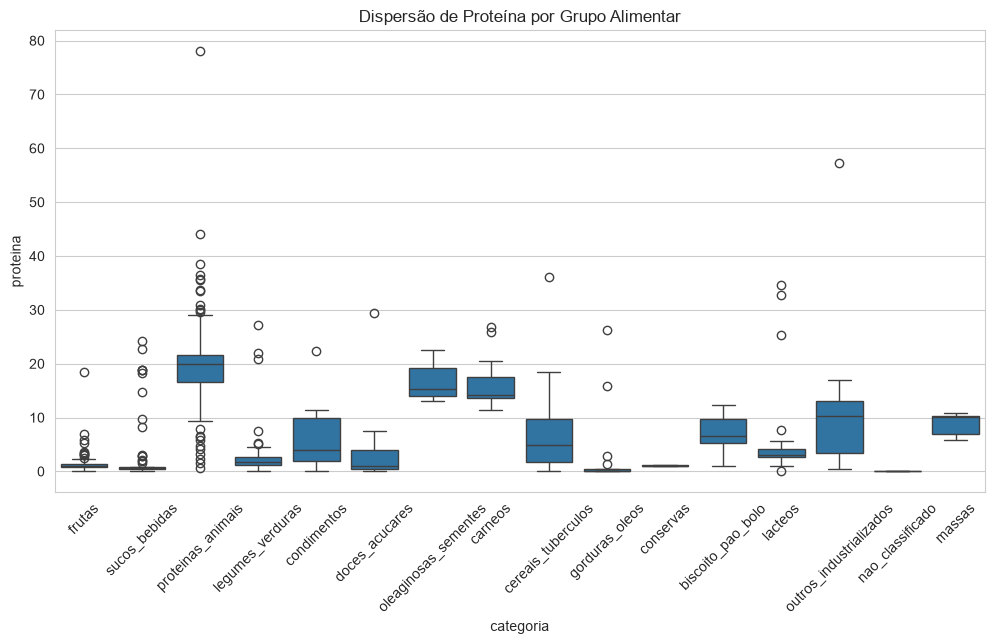


6. Variabilidade Nutricional (Coeficiente de Variação %):


sodio           576.012950
lipideos        327.182396
ferro           322.401486
calcio          238.747022
proteina        123.604814
carboidratos    119.848663
energia          92.879717
dtype: float64


7. Verificação de Inconsistências (Máximos por Grupo):


,proteina,energia,sodio
categoria,,,
biscoito_pao_bolo,12.350000,513.446183,854.356667
carneos,26.900000,592.531175,1943.000000
cereais_tuberculos,36.030100,545.700000,1163.257000
condimentos,22.400000,558.860000,39943.000000
conservas,1.162500,194.153847,1567.000000
doces_acucares,29.420000,558.876333,1794.000000
frutas,18.509367,660.000000,412.000000
gorduras_oleos,26.187500,902.000000,894.000000
lacteos,34.690000,496.650300,1263.130000


In [111]:
# 1. Distribuição de Proteínas por Grupo (Visualização)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='categoria', y='proteina')
plt.xticks(rotation=45)
plt.title('Dispersão de Proteína por Grupo Alimentar')
plt.show()

# 2. Variabilidade e Dispersão (Coeficiente de Variação - CV)
# CV = (Desvio Padrão / Média) * 100. Acima de 30% indica alta heterogeneidade.
nutrientes = ['energia', 'proteina', 'lipideos', 'carboidratos', 'calcio', 'ferro', 'sodio']
cv_analise = (df[nutrientes].std() / df[nutrientes].mean()) * 100

print("\n6. Variabilidade Nutricional (Coeficiente de Variação %):")
display(cv_analise.sort_values(ascending=False))

# 3. Inconsistências: Grupo vs Composição
# Exemplo: Checar se existem 'frutas' com proteínas absurdamente altas (possível erro de cadastro)
print("\n7. Verificação de Inconsistências (Máximos por Grupo):")
display(df.groupby('categoria')[['proteina', 'energia', 'sodio']].max())

## Clusterização e similiaridade nutricional
### Scaling: normalization, standardization, robust
Scaling ajusta os dados para que eles estejam dentro de uma determinada faixa ou distribuição.

In [112]:
import os
# Fix para o UserWarning de K-Means no Windows
os.environ["OMP_NUM_THREADS"] = "1" 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

# 1. Preparação e Scaling
# Garantimos que os dados estão normalizados para o algoritmo (Média 0, DP 1)
features = ['energia', 'proteina', 'lipideos', 'carboidratos', 'calcio', 'ferro', 'retinol', 'vitamina_c', 'sodio']
X_scaled = StandardScaler().fit_transform(df[features])

# 2. Clusterização Nutricional
# Definimos 6 clusters para agrupar comportamentos semelhantes
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)
df['cluster_nutricional'] = kmeans.fit_predict(X_scaled)

# 3. Função Robusta de Similaridade
def encontrar_substitutos(termo_busca, top_n=5):
    """
    Busca alimentos nutricionalmente semelhantes usando Distância de Cosseno.
    """
    try:
        # Busca flexível pelo nome do alimento
        mascara = df['alimento'].str.contains(termo_busca, case=False, na=False)
        if not mascara.any():
            return f"Nenhum alimento encontrado com o termo: {termo_busca}"
        
        idx = df[mascara].index[0]
        alimento_alvo = df.iloc[idx]['alimento']
        
        # Cálculo de Similaridade
        sim_matrix = cosine_similarity(X_scaled)
        scores = list(enumerate(sim_matrix[idx]))
        scores = sorted(scores, key=lambda x: x[1], reverse=True)
        
        indices = [i[0] for i in scores[1:top_n+1]]
        result = df.iloc[indices][['alimento', 'categoria', 'restricao_pnae', 'sdn_score']]
        
        print(f"--- Alimentos semelhantes a: {alimento_alvo} ---")
        return result
    except Exception as e:
        return f"Erro na busca: {e}"

# Execução do teste solicitado
display(encontrar_substitutos("Feijão carioca"))

'Nenhum alimento encontrado com o termo: Feijão carioca'

## Variabilidade e Redução de Dimensionalidade (PCA)

### Redução de dimensionalidade
A redução de dimensionalidade é usada para reduzir o número de variáveis de entrada, mantendo a maior parte da informação.
A PCA é um método comum, que transforma as variáveis originais em um conjunto de variáveis não correlacionadas chamadas componentes principais.<br>
https://en.wikipedia.org/wiki/Dimensionality_reduction

O PCA identifica quais nutrientes realmente "explicam" a diferença entre os alimentos, ajudando a simplificar o modelo.

C:\Users\dba14\AppData\Local\Temp\ipykernel_13492\855008508.py:12: UserWarning: 
The palette list has fewer values (15) than needed (16) and will cycle, which may produce an uninterpretable plot.
  sns.scatterplot(x='pca_1', y='pca_2', hue='categoria', data=df, palette=pal, alpha=0.6, style='is_restrito')


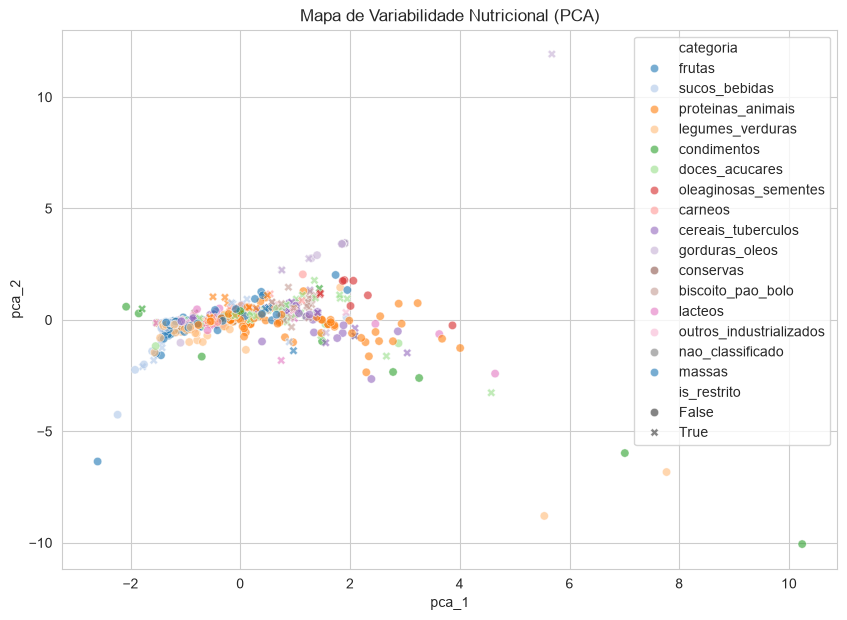

Nutrientes que mais explicam a variabilidade (PC1):


energia         0.539977
calcio          0.442787
ferro           0.435054
proteina        0.351357
carboidratos    0.343847
lipideos        0.266062
retinol         0.029408
sodio          -0.038744
vitamina_c     -0.090859
Name: PC1, dtype: float64

In [113]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)

df['pca_1'] = pca_result[:, 0]
df['pca_2'] = pca_result[:, 1]

# Visualização da Variabilidade
plt.figure(figsize=(10, 7))
pal = sns.color_palette("tab20", 15)
sns.scatterplot(x='pca_1', y='pca_2', hue='categoria', data=df, palette=pal, alpha=0.6, style='is_restrito')
plt.title('Mapa de Variabilidade Nutricional (PCA)')
plt.show()

# Importância das Features na Variabilidade
importancia_features = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=features)
print("Nutrientes que mais explicam a variabilidade (PC1):")
display(importancia_features['PC1'].sort_values(ascending=False))

## Ultraprocessados

In [114]:
# Identificação de "Perfil Ultraprocessado" via Outliers de Sódio/Energia
# Alimentos que fogem do padrão de sua categoria original
df['perfil_processado_score'] = (df['sodio'] / (df['proteina'] + 1)) * (df['energia'] / 100)

print("Top Alimentos com Perfil de Ultraprocessado:")
display(df.nlargest(10, 'perfil_processado_score')[['alimento', 'restricao_pnae', 'categoria']])


Top Alimentos com Perfil de Ultraprocessado:


,alimento,restricao_pnae,categoria
121,"Caldo de galinha, tablete",Aquisição proibida,proteinas_animais
255,"Fermento em pó, químico",Sem restrição,outros_industrializados
120,"Caldo de carne, tablete",Aquisição proibida,proteinas_animais
384,"Margarina com óleo hidrogenado, com sal (65% d...",Aquisição proibida,gorduras_oleos
386,"Margarina, com óleo interesterificado, com sal...",Oferta limitada para > 3 anos e proibida para ...,gorduras_oleos
378,"Manteiga, com sal",Sem restrição,gorduras_oleos
501,"Pudim, mistura p/, diet (média diferentes sabo...",Aquisição proibida,doces_acucares
554,Tempero a base de sal,Aquisição proibida,condimentos
361,"Maionese, tradicional com ovos",Aquisição proibida,proteinas_animais
65,"Azeitona, preta, conserva",Oferta limitada para todas as idades,conservas


## Dominância nutricional
Alimentos que dominam múltiplos nutrientes simultaneamente
Alimentos que dominam múltiplos nutrientes (alto SDN e alta Dominância) devem ser os alvos prioritários de compra (provavelmente), pois garantem a segurança nutricional com o menor volume de itens.

In [115]:
# Dominância Multidirecional (Alimentos que dominam múltiplos nutrientes)
# Calculamos o Z-score de cada nutriente e somamos
for col in features:
    df[f'z_{col}'] = (df[col] - df[col].mean()) / df[col].std()

# Dominância = Soma de Z-scores positivos (Nutrientes desejáveis)
df['dominancia_nutricional'] = df[['z_proteina', 'z_calcio', 'z_ferro', 'z_vitamina_c', 'z_retinol']].sum(axis=1)

print("\nAlimentos que dominam múltiplos nutrientes simultaneamente:")
display(df.nlargest(10, 'dominancia_nutricional')[['alimento', 'dominancia_nutricional', 'restricao_pnae']])


Alimentos que dominam múltiplos nutrientes simultaneamente:


,alimento,dominancia_nutricional,restricao_pnae
534,Salsinha seca,24.754829,Sem restrição
204,Coentro,22.156438,Sem restrição
516,Quindim,18.289402,Oferta limitada para > 3 anos e proibida para ...
205,"Coentro, folhas desidratadas",16.946389,Sem restrição
435,Orégano,14.719938,Sem restrição
23,"Acerola, crua",13.098375,Sem restrição
524,"Rúcula, crua",11.805801,Sem restrição
342,"Leite, de vaca, desnatado, pó",8.963705,Sem restrição
24,"Acerola, polpa, congelada",8.045299,Sem restrição
505,Queijo ralado,8.004679,Sem restrição


## Outros

In [116]:
# Planejamento Estratégico de Cardápios


# 1. Metas de Proteína e Ferro (Específico para Crescimento)
print("Top 10 Alimentos para Metas de Ferro (Sem Restrição):")
display(df[df['restricao_pnae'] == 'Sem restrição'].nlargest(10, 'ferro')[['alimento', 'ferro', 'sdn_score']])

# 2. Substitutos de Baixo Custo (Lógica: SDN alto em categorias baratas como Ovos/Leguminosas)
print("\nAlimentos de Alta Densidade Nutricional (Ideal para Baixo Custo):")
display(df[df['categoria'].isin(['proteinas_animais', 'cereais_tuberculos'])].nlargest(10, 'sdn_score'))

# 3. Alerta de Sódio (O que evitar em excesso)
print("\nTop 10 Alimentos com Sódio Crítico:")
display(df.nlargest(10, 'sodio')[['alimento', 'sodio', 'restricao_pnae']])

# 4. Enriquecimento Vegetariano (Filtro por Proteína em itens de Origem Vegetal)
print("\nMelhores Fontes de Proteína Vegetal:")
display(df[df['origem'] == 'Vegetal'].nlargest(10, 'proteina')[['alimento', 'proteina', 'categoria']])

Top 10 Alimentos para Metas de Ferro (Sem Restrição):


,alimento,ferro,sdn_score
534,Salsinha seca,97.900000,0.007515
205,"Coentro, folhas desidratadas",81.431333,0.004426
435,Orégano,44.000000,0.004904
204,Coentro,42.460000,0.006552
126,Canela em pó,38.200000,0.001606
232,"Farinha, de arroz, enriquecida",31.383333,0.001389
476,Pimenta em pó,28.860000,0.002322
54,"Arroz, farelo",18.800000,0.000704
251,"Feijão, rajado, cru",18.581667,0.000797
236,"Farinha, de mesocarpo de babaçu, crua",18.333667,0.000685



Alimentos de Alta Densidade Nutricional (Ideal para Baixo Custo):


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae,pode_precificar,motivo_exclusao,descricao_normalizada,produto_base,categoria,quantidade_embalagem,unidade_medida,norm_calcio,norm_ferro,norm_retinol,norm_vitamina_c,sdn_score,relacao_proteina_caloria,estado_preparo,origem,is_restrito,cluster_nutricional,pca_1,pca_2,perfil_processado_score,z_energia,z_proteina,z_lipideos,z_carboidratos,z_calcio,z_ferro,z_retinol,z_vitamina_c,z_sodio,dominancia_nutricional
315,"Lambari, congelado, cru",130.840311,547.4358612636917,16.812500,6.546667,0.000000,1181.277000,0.905667,4.306667,0.00,47.920000,Sem restrição,True,,lambari congelado cru,lambari,proteinas_animais,NaN,kg,0.749541,0.009251,0.000039,0.000000,0.005756,0.128487,cru,Animal,False,0,2.296840,-2.349701,3.519926,-0.373117,0.948968,-0.106332,-0.834386,5.704238,-0.176963,-0.093032,-0.286286,-0.156460,6.096924
131,"Caranguejo, cozido",82.721502,346.10676230879665,18.479167,0.423000,0.000000,357.152667,2.861667,0.000000,0.00,360.105667,Sem restrição,False,preparacao_detectada:\b(cozid[ao]|assad[ao]|fr...,caranguejo cozido,caranguejo,cereais_tuberculos,NaN,kg,0.226620,0.029231,0.000000,0.000000,0.003056,0.223363,cozido,Vegetal,False,1,0.396440,-0.967421,15.292482,-0.631857,1.123243,-0.292762,-0.834386,1.432430,0.110733,-0.093784,-0.286286,-0.044752,2.286336
473,"Pescadinha, crua",76.408908,319.6948724666667,15.479167,1.143333,0.000000,331.597333,0.547000,0.000000,0.00,120.338667,Sem restrição,True,,pescadinha crua,pescadinha,proteinas_animais,NaN,kg,0.210404,0.005587,0.000000,0.000000,0.002790,0.202557,cru,Animal,False,1,0.070003,-0.749936,5.579740,-0.665801,0.809548,-0.270832,-0.834386,1.299965,-0.229717,-0.093784,-0.286286,-0.130547,1.499726
124,"Camarão, Sete Barbas, sem cabeça, com casca, f...",231.246154,967.5339077120541,18.387500,15.620333,2.879833,959.701333,2.439000,0.000000,0.00,99.055000,Sem restrição,False,preparacao_detectada:\b(cozid[ao]|assad[ao]|fr...,camarao sete barbas sem cabeca com casca frito,camarao sete barbas sem cabeca com casca frito,proteinas_animais,NaN,kg,0.608948,0.024913,0.000000,0.000000,0.002729,0.079511,natural_ou_outros,Animal,False,0,2.343837,-1.632169,11.814874,0.166778,1.113658,0.169908,-0.731927,4.555711,0.048566,-0.093784,-0.286286,-0.138163,5.337865
316,"Lambari, fresco, cru",151.598347,634.2874817694642,15.652083,9.397333,0.000000,590.272000,0.631333,0.000000,0.00,41.109333,Sem restrição,True,,lambari fresco cru,lambari fresco,proteinas_animais,NaN,kg,0.374538,0.006449,0.000000,0.000000,0.002497,0.103240,cru,Animal,False,0,0.962489,-1.000345,3.742539,-0.261498,0.827629,-0.019546,-0.834386,2.640793,-0.217313,-0.093784,-0.286286,-0.158897,2.871039
444,"Palmito, juçara, em conserva",23.199716,97.06761356019635,1.791667,0.403333,4.328333,58.289000,0.303333,0.000000,1.98,513.820333,Oferta limitada para todas as idades,True,,palmito jucara em conserva,palmito jucara em conserva,cereais_tuberculos,NaN,kg,0.036985,0.003098,0.000000,0.002103,0.001743,0.077195,conserva,Vegetal,True,2,-1.192657,-0.234765,42.700248,-0.951914,-0.621684,-0.293361,-0.680393,-0.116715,-0.265557,-0.093784,-0.255129,0.010251,-1.352869
508,"Queijo, mozarela",329.870718,1380.1790858729917,22.649000,25.183000,3.049333,875.039333,0.306000,109.000000,0.00,581.000000,Sem restrição,True,,queijo mozarela,queijo mozarela,proteinas_animais,NaN,kg,0.555228,0.003126,0.000985,0.000000,0.001691,0.068658,natural_ou_outros,Animal,False,0,2.529528,-0.951399,81.041433,0.697095,1.559262,0.461036,-0.725897,4.116870,-0.265165,-0.074765,-0.286286,0.034290,5.049916
512,"Queijo, prato",359.880462,1505.7398547027492,22.661760,29.106333,1.878573,939.993333,0.280000,122.666667,0.00,580.000000,Sem restrição,True,,queijo prato,queijo prato,proteinas_animais,NaN,kg,0.596442,0.002860,0.001108,0.000000,0.001664,0.062968,natural_ou_outros,Animal,False,0,2.782305,-0.955882,88.214344,0.858461,1.560596,0.580478,-0.767550,4.453556,-0.268989,-0.072381,-0.286286,0.


Top 10 Alimentos com Sódio Crítico:


,alimento,sodio,restricao_pnae
527,"Sal, grosso",39943.000000,Sem restrição
554,Tempero a base de sal,32560.000000,Aquisição proibida
526,"Sal, dietético",23432.000000,Sem restrição
121,"Caldo de galinha, tablete",22300.000000,Aquisição proibida
120,"Caldo de carne, tablete",22180.000000,Aquisição proibida
67,"Bacalhau, salgado, cru",13585.056667,Sem restrição
255,"Fermento em pó, químico",10052.000000,Sem restrição
145,"Carne, bovina, charque, cru",5875.000000,Sem restrição
540,Shoyu,5064.000000,Aquisição proibida
416,"Molho, soja, shoyu",5025.000000,Aquisição proibida



Melhores Fontes de Proteína Vegetal:


,alimento,proteina,categoria
543,"Soja, farinha",36.030100,cereais_tuberculos
50,"Amendoim, grão, cru",27.190800,legumes_verduras
51,"Amendoim, torrado, salgado",22.500000,oleaginosas_sementes
204,Coentro,21.930000,legumes_verduras
278,"Gergelim, semente",21.164667,oleaginosas_sementes
205,"Coentro, folhas desidratadas",20.875000,legumes_verduras
49,"Amêndoa, torrada, salgada",18.554759,oleaginosas_sementes
172,"Castanha-de-caju, torrada, salgada",18.509367,frutas
131,"Caranguejo, cozido",18.479167,cereais_tuberculos
569,"Trigo, farelo",17.500000,cereais_tuberculos


In [117]:

# Avançado: Análise de Padrões e Outliers para Identificação de Ultraprocessados e Alimentos Dominantes

# 1. Coeficiente de Variação (Dispersão Estatística)
cv = (df[features].std() / df[features].mean()) * 100
print("Dispersão dos Nutrientes (Coeficiente de Variação %):")
display(cv.sort_values(ascending=False))

# 2. Identificação de Ultraprocessados (Score Nutricional de Processamento)
# Lógica: (Sódio / Proteína) * (Caloria / 100). Alta densidade calórica + Sódio + Baixa Proteína.
df['score_processamento'] = (df['sodio'] + 1) / (df['proteina'] + 1) * (df['energia'] / 100)

print("\nAlimentos com perfil nutricional compatível com Ultraprocessados:")
display(df.nlargest(10, 'score_processamento')[['alimento', 'score_processamento', 'restricao_pnae']])

# 3. Dominância de Múltiplos Nutrientes
# Alimentos que estão no Top 25% em mais de 3 nutrientes desejáveis
desejaveis = ['proteina', 'calcio', 'ferro', 'vitamina_c']
df['dominancia_count'] = (df[desejaveis] > df[desejaveis].quantile(0.75)).sum(axis=1)

print("\nAlimentos que dominam múltiplos nutrientes desejáveis simultaneamente:")
display(df[df['dominancia_count'] >= 3][['alimento', 'dominancia_count', 'categoria']])

Dispersão dos Nutrientes (Coeficiente de Variação %):


retinol         1066.281273
sodio            576.012950
vitamina_c       349.300749
lipideos         327.182396
ferro            322.401486
calcio           238.747022
proteina         123.604814
carboidratos     119.848663
energia           92.879717
dtype: float64


Alimentos com perfil nutricional compatível com Ultraprocessados:


,alimento,score_processamento,restricao_pnae
121,"Caldo de galinha, tablete",7667.878082,Aquisição proibida
255,"Fermento em pó, químico",6113.709523,Sem restrição
120,"Caldo de carne, tablete",6074.569318,Aquisição proibida
384,"Margarina com óleo hidrogenado, com sal (65% d...",5334.200000,Aquisição proibida
386,"Margarina, com óleo interesterificado, com sal...",3339.615743,Oferta limitada para > 3 anos e proibida para ...
378,"Manteiga, com sal",2974.767179,Sem restrição
501,"Pudim, mistura p/, diet (média diferentes sabo...",2375.927273,Aquisição proibida
554,Tempero a base de sal,1848.056757,Aquisição proibida
361,"Maionese, tradicional com ovos",1505.747415,Aquisição proibida
65,"Azeitona, preta, conserva",1407.783732,Oferta limitada para todas as idades



Alimentos que dominam múltiplos nutrientes desejáveis simultaneamente:


,alimento,dominancia_count,categoria
19,Açafrão,3,condimentos
27,Achocolatado em pó diet,3,doces_acucares
33,"Agrião, cru",3,legumes_verduras
49,"Amêndoa, torrada, salgada",3,oleaginosas_sementes
111,"Café, pó, torrado",3,sucos_bebidas
124,"Camarão, Sete Barbas, sem cabeça, com casca, f...",3,proteinas_animais
131,"Caranguejo, cozido",3,cereais_tuberculos
170,"Carne, frango, caipira, inteiro, s/ pele, cozi...",3,proteinas_animais
173,"Castanha-do-Brasil, crua",3,oleaginosas_sementes
181,"Cereais, mingau, milho, infantil",3,doces_acucares


## Encoding: várias estratégias de encoding para variáveis categóricas
Encoding transforma variáveis categóricas em numéricas, necessárias para a maioria dos modelos de ML.

## Bloco: Classificação de ingredientes de receita (`is_ingrediente`)

Alimentos que **não são palatáveis de forma isolada** — temperos, gorduras puras,
farinhas de espessamento, sal, óleos — devem ser excluídos do otimizador como
itens autônomos de cardápio, mas **mantidos na base** para fins de precificação
de receitas e matching de preços.

A flag `is_ingrediente = True` sinaliza esses itens. O critério combina:

1. **Lista curada por categoria** — categorias que por natureza são ingredientes
   (`condimentos`, `gorduras_oleos`, parte de `cereais_tuberculos` e `outros_industrializados`)
2. **Lista curada por nome** — itens específicos que escapam à categoria
   mas não são consumíveis de forma isolada (ex.: fermento, gelatina, leite de coco)
3. **Padrões textuais** — termos como "tempero", "farinha", "polvilho", "goma",
   "extrato", "vinagre", "cacau em pó", "amido"

> **Como usar no Módulo 5 (solver):**
> Filtrar `df[df['is_ingrediente'] == False]` antes de construir o modelo de PL.
> Itens com `is_ingrediente = True` continuam no matching de preços (Módulo 3)
> para compor o custo estimado de receitas, mas não entram como variáveis de decisão.


In [118]:
# ═══════════════════════════════════════════════════════════════════════════════
# BLOCO — FLAG is_ingrediente
# Identifica alimentos que são ingredientes de receita, não consumíveis isolados.
# ═══════════════════════════════════════════════════════════════════════════════

import unicodedata, re

def _norm(texto):
    """Normaliza para comparação: minúsculas, sem acentos, sem pontuação."""
    if not isinstance(texto, str):
        return ''
    t = unicodedata.normalize('NFD', texto.lower())
    t = ''.join(c for c in t if unicodedata.category(c) != 'Mn')
    return re.sub(r'[^a-z0-9 ]', ' ', t).strip()

# ── 1. Categorias que são intrinsecamente ingredientes ────────────────────────
CATEGORIAS_INGREDIENTE = {
    'condimentos',           # sal, pimenta, alho, cebola, temperos, ervas
    'gorduras_oleos',        # óleo, margarina, banha, azeite, manteiga, gordura
    'outros_industrializados', # fermento, gelatina, sopa desidratada, shoyu etc.
}

# ── 2. Subcategorias de cereais_tuberculos que são ingredientes ───────────────
# (farinha, polvilho, goma, tapioca, amido, fubá — não são pratos)
TERMOS_CEREAL_INGREDIENTE = [
    'farinha', 'polvilho', 'goma', 'amido', 'fuba', 'fubá',
    'tapioca po', 'tapioca em po', 'trigo integral po',
    'aveia em flocos', 'aveia em po', 'canjica po', 'quinoa po',
]

# ── 3. Lista curada por nome (escapa à categoria mas não é consumível isolado) ─
NOMES_INGREDIENTE_CURADOS = {
    # Gorduras e óleos específicos
    'banha suina', 'banha de porco', 'gordura vegetal', 'gordura de coco',
    'manteiga de cacao', 'manteiga de cacau', 'gordura hidrogenada',
    'creme de leite', 'leite de coco', 'extrato de tomate', 'extrato de soja',
    # Condimentos e temperos
    'coentro', 'salsa', 'cebolinha', 'louro', 'oregano', 'alecrim',
    'tomilho', 'canela em pau', 'canela em po', 'cravo da india',
    'cominho', 'pimenta do reino', 'pimenta calabresa', 'pimenta branca',
    'curcuma', 'acafrao', 'colorau', 'colorificio', 'urucum',
    'noz moscada', 'baunilha', 'essencia de baunilha',
    'tempero pronto', 'tempero completo', 'caldo de galinha',
    'caldo de carne', 'caldo de legumes', 'sazon',
    # Espessantes e fermentos
    'fermento biologico', 'fermento quimico', 'fermento em po',
    'bicarbonato de sodio', 'bicarbonato', 'gelatina em po',
    'gelatina incolor', 'agar agar', 'amido de milho',
    # Vinagres e conservantes
    'vinagre', 'vinagre de vinho', 'vinagre de alcool',
    # Cacau e derivados (pó — não chocolate para consumo)
    'cacau em po', 'cacau solúvel', 'cacau soluvel',
    # Sal
    'sal refinado', 'sal grosso', 'sal iodado', 'sal light',
    # Shoyu e molhos
    'shoyu', 'molho shoyu', 'molho de soja',
    'molho inglês', 'molho ingles', 'molho worcester',
    'tabasco', 'molho de pimenta',
    # Outros
    'adocante liquido', 'adocante em po', 'steviosideo',
    'sucralose', 'aspartame',
    'lecitina de soja',
}

# ── 4. Padrões textuais (regex sobre descricao_normalizada ou alimento) ───────
PADROES_INGREDIENTE = [
    r'\bfarinha\b',
    r'\bpolvilho\b',
    r'\bgoma\s*(de\s*)?tapioca\b',
    r'\bamido\b',
    r'\bextrato\b',
    r'\bconcentrado\b',
    r'\bessencia\b',
    r'\btempero\b',
    r'\bcondimento\b',
    r'\bcolorau\b',
    r'\burucum\b',
    r'\bfermento\b',
    r'\bbicarbonato\b',
    r'\bvinagre\b',
    r'\bshoyu\b',
    r'\bmolho\b',
    r'\bcaldo\b',
    r'\bazeite\b',
    r'\boleo\b',
    r'\bmanteiga\b',
    r'\bbanha\b',
    r'\bnata\b',    
    r'\bmargarina\b',
]

def classificar_ingrediente(row):
    """
    Retorna (is_ingrediente: bool, motivo: str).

    Hierarquia de decisão:
      1. Categoria intrínseca de ingrediente
      2. Subcategoria cereal com termos de ingrediente
      3. Nome curado
      4. Padrão textual
    """
    categoria  = str(row.get('categoria', '')).lower()
    nome_norm  = _norm(str(row.get('alimento', '')))
    desc_norm  = _norm(str(row.get('descricao_normalizada', row.get('alimento', ''))))

    # 1. Categoria intrínseca
    if categoria in CATEGORIAS_INGREDIENTE:
        return True, f'categoria:{categoria}'

    # 2. Cereal com termos de ingrediente
    if categoria == 'cereais_tuberculos':
        for termo in TERMOS_CEREAL_INGREDIENTE:
            if termo in nome_norm or termo in desc_norm:
                return True, f'cereal_ingrediente:{termo}'

    # 3. Nome curado (match parcial sobre nome normalizado)
    for nome_curado in NOMES_INGREDIENTE_CURADOS:
        if nome_curado in nome_norm:
            return True, f'nome_curado:{nome_curado}'

    # 4. Padrão textual
    for padrao in PADROES_INGREDIENTE:
        if re.search(padrao, nome_norm):
            return True, f'padrao_regex:{padrao}'
        if re.search(padrao, desc_norm):
            return True, f'padrao_regex_desc:{padrao}'

    return False, ''

# ── Aplicar classificação ─────────────────────────────────────────────────────
resultado = df.apply(classificar_ingrediente, axis=1, result_type='expand')
df['is_ingrediente']       = resultado[0]
df['motivo_ingrediente']   = resultado[1]

# ── Relatório de cobertura ────────────────────────────────────────────────────
n_ing  = df['is_ingrediente'].sum()
n_tot  = len(df)
n_sol  = (~df['is_ingrediente']).sum()

print(f"{'═'*60}")
print(f"RELATÓRIO — Flag is_ingrediente")
print(f"{'═'*60}")
print(f"  Total de alimentos          : {n_tot}")
print(f"  Ingredientes de receita     : {n_ing:>4}  ({n_ing/n_tot*100:.1f} %)")
print(f"  Consumíveis como prato      : {n_sol:>4}  ({n_sol/n_tot*100:.1f} %)")
print()

print("Por categoria:")
resumo_cat = (
    df.groupby('categoria')['is_ingrediente']
    .agg(total='count', ingredientes='sum')
    .assign(pct=lambda x: (x['ingredientes'] / x['total'] * 100).round(1))
    .sort_values('ingredientes', ascending=False)
)
display(resumo_cat)

print("Por restrição:")
resumo_restricao = (
    df.groupby('restricao_pnae')['is_ingrediente']
    .agg(total='count', ingredientes='sum')
    .assign(pct=lambda x: (x['ingredientes'] / x['total'] * 100).round(1))
    .sort_values('ingredientes', ascending=False)
)
display(resumo_restricao)

print("\nAmostra de ingredientes identificados:")
display(
    df[df['is_ingrediente']]
    [['alimento', 'categoria', 'motivo_ingrediente']]
    .head(40)
    .reset_index(drop=True)
)

print("\n⚠ Verifique a lista acima e adicione itens à")
print("  NOMES_INGREDIENTE_CURADOS ou PADROES_INGREDIENTE conforme necessário.")


════════════════════════════════════════════════════════════
RELATÓRIO — Flag is_ingrediente
════════════════════════════════════════════════════════════
  Total de alimentos          : 583
  Ingredientes de receita     :   82  (14.1 %)
  Consumíveis como prato      :  501  (85.9 %)

Por categoria:


,total,ingredientes,pct
categoria,,,
gorduras_oleos,20,20,100.0
condimentos,14,14,100.0
cereais_tuberculos,57,14,24.6
legumes_verduras,64,9,14.1
outros_industrializados,8,8,100.0
proteinas_animais,122,6,4.9
sucos_bebidas,79,5,6.3
biscoito_pao_bolo,27,2,7.4
lacteos,23,2,8.7


Por restrição:


,total,ingredientes,pct
restricao_pnae,,,
Sem restrição,417,57,13.7
Aquisição proibida,49,16,32.7
Oferta limitada para todas as idades,22,5,22.7
Oferta limitada para > 3 anos e proibida para ≤ 3 anos,95,4,4.2



Amostra de ingredientes identificados:


,alimento,categoria,motivo_ingrediente
0,Açafrão,condimentos,categoria:condimentos
1,"Alho, cru",condimentos,categoria:condimentos
2,"Alho-poró, cru",condimentos,categoria:condimentos
3,Almôndega ao molho em conserva,proteinas_animais,padrao_regex:\bmolho\b
4,"Atum, conserva em óleo",gorduras_oleos,categoria:gorduras_oleos
5,"Azeite, de dendê",gorduras_oleos,categoria:gorduras_oleos
6,"Azeite, de oliva, extra virgem",gorduras_oleos,categoria:gorduras_oleos
7,Banha suína,gorduras_oleos,categoria:gorduras_oleos
8,Biscoito de polvilho,biscoito_pao_bolo,padrao_regex:\bpolvilho\b
9,Biscoito de polvilho doce,biscoito_pao_bolo,padrao_regex:\bpolvilho\b



⚠ Verifique a lista acima e adicione itens à
  NOMES_INGREDIENTE_CURADOS ou PADROES_INGREDIENTE conforme necessário.


In [119]:
print(df.groupby(['is_ingrediente', 'pode_precificar']).size())
# Mostrar registros com pode_precificar=False e is_ingrediente=False
nao_precificaveis_nao_ingredientes = df[
    (df["pode_precificar"] == False) &
    (df["is_ingrediente"] == False)
]

print(f"Quantidade: {len(nao_precificaveis_nao_ingredientes)}")
display(nao_precificaveis_nao_ingredientes.head())

print(f"Prévia (sem excluir do arquivo): {(~df.is_ingrediente & df.pode_precificar).sum()} "
        f"alimentos consumíveis com precificação viável, de {len(df)} no total.")

is_ingrediente  pode_precificar
False           False              103
                True               398
True            False               17
                True                65
dtype: int64
Quantidade: 103


,alimento,energia,nan,proteina,lipideos,carboidratos,calcio,ferro,retinol,vitamina_c,sodio,restricao_pnae,pode_precificar,motivo_exclusao,descricao_normalizada,produto_base,categoria,quantidade_embalagem,unidade_medida,norm_calcio,norm_ferro,norm_retinol,norm_vitamina_c,sdn_score,relacao_proteina_caloria,estado_preparo,origem,is_restrito,cluster_nutricional,pca_1,pca_2,perfil_processado_score,z_energia,z_proteina,z_lipideos,z_carboidratos,z_calcio,z_ferro,z_retinol,z_vitamina_c,z_sodio,dominancia_nutricional,score_processamento,dominancia_count,is_ingrediente,motivo_ingrediente
1,"Abacaxi, banana e cenoura, suco natural (nécta...",64.0,267.776,0.57,0.14,15.70,10.50,0.26,235.0,7.96,5.19,Oferta limitada para > 3 anos e proibida para ...,False,preparacao_detectada:\bc\/\s,abacaxi banana e cenoura suco natural nectar c...,abacaxi banana e cenoura suco natural nectar c...,sucos_bebidas,NaN,l,0.006662,0.002656,0.002123,0.008456,0.000306,0.008905,suco_nectar,Outros/Processados,True,2,-1.094760,-0.092470,2.115669,-0.732525,-0.749428,-0.301378,-0.275812,-0.364427,-0.271930,-0.052781,-0.161026,-0.171750,-1.599592,2.523312,0,False,
2,"Abacaxi, banana e cenoura, suco natural (nécta...",28.0,117.152,0.61,0.15,6.59,11.30,0.28,261.0,8.82,4.43,Sem restrição,False,preparacao_detectada:\be\s+\w+,abacaxi banana e cenoura suco natural nectar s...,abacaxi banana e cenoura suco natural nectar s...,sucos_bebidas,NaN,l,0.007170,0.002860,0.002358,0.009369,0.000750,0.021778,suco_nectar,Outros/Processados,False,2,-1.307335,-0.176593,0.770435,-0.926102,-0.745245,-0.301073,-0.599927,-0.360280,-0.268989,-0.048244,-0.147493,-0.172022,-1.570252,0.944348,0,False,
4,"Abacaxi, maracujá e caju, suco natural (néctar...",70.0,292.88,0.55,0.23,16.70,9.47,0.33,22.3,53.00,14.50,Oferta limitada para > 3 anos e proibida para ...,False,preparacao_detectada:\bc\/\s,abacaxi maracuja e caju suco natural nectar c ...,abacaxi maracuja e caju suco natural nectar c ...,sucos_bebidas,NaN,l,0.006009,0.003371,0.000201,0.056301,0.000928,0.007856,suco_nectar,Outros/Processados,True,2,-1.128643,-0.380961,6.548387,-0.700263,-0.751519,-0.298638,-0.240234,-0.369766,-0.261635,-0.089893,0.547731,-0.168419,-0.925082,7.000000,1,False,
5,"Abacaxi, melão e maracujá, suco natural (nécta...",63.0,263.592,0.59,0.20,15.00,7.74,0.29,21.6,15.60,9.17,Oferta limitada para > 3 anos e proibida para ...,False,preparacao_detectada:\bc\/\s,abacaxi melao e maracuja suco natural nectar c...,abacaxi melao e maracuja suco natural nectar c...,sucos_bebidas,NaN,l,0.004911,0.002962,0.000195,0.016572,0.000385,0.009364,suco_nectar,Outros/Processados,True,2,-1.121518,-0.141990,3.633396,-0.737902,-0.747337,-0.299551,-0.300717,-0.378733,-0.267518,-0.090015,-0.040802,-0.170326,-1.524405,4.029623,1,False,
6,"Abacaxi, melão e maracujá, suco natural (nécta...",36.0,150.624,0.63,0.22,8.17,8.10,0.31,23.4,16.80,8.94,Sem restrição,False,preparacao_detectada:\be\s+\w+,abacaxi melao e maracuja suco natural nectar s...,abacaxi melao e maracuja suco natural nectar s...,sucos_bebidas,NaN,l,0.005140,0.003166,0.000211,0.017846,0.000713,0.017495,suco_nectar,Outros/Processados,False,2,-1.281570,-0.208577,1.974479,-0.883085,-0.743154,-0.298942,-0.543714,-0.376867,-0.264576,-0.089701,-0.021919,-0.170408,-1.496217,2.195337,1,False,


Prévia (sem excluir do arquivo): 398 alimentos consumíveis com precificação viável, de 583 no total.


In [120]:

# Remove as linhas
df = df[df["restricao_pnae"] != "Aquisição proibida"]

# Distribuição das restrições

print("\nDistribuição das restrições:")

display(
    df["restricao_pnae"]
    .value_counts()
)


# A flag 'is_ingrediente' já está incorporada — o solver (Módulo 5) filtrará
# df[df['is_ingrediente'] == False] antes de construir o modelo de PL.

# Exportação para futuras integrações com Painel de Preços / PNCP / BI

df.to_csv(
    output_folder + 'pnae_alimentos_naoproibidos.csv',
    index=False,
    encoding='utf-8-sig'
)
df.to_excel(output_folder + "pnae_alimentos_naoproibidos.xlsx", index=False)

print('Arquivos exportados:')
print('- pnae_alimentos_naoproibidos.csv')
print('- pnae_alimentos_naoproibidos.xlsx')


Distribuição das restrições:


restricao_pnae
Sem restrição                                             417
Oferta limitada para > 3 anos e proibida para ≤ 3 anos     95
Oferta limitada para todas as idades                       22
Name: count, dtype: int64

Arquivos exportados:
- pnae_alimentos_naoproibidos.csv
- pnae_alimentos_naoproibidos.xlsx
